# Daily norms calculations

### Imports

In [1]:
%load_ext autoreload
%autoreload 2

In [61]:
import polars as pl
from datetime import date
from statsmodels.nonparametric.smoothers_lowess import lowess
import numpy as np
import datetime
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

import climato.config as config
from climato.sources.meteo_france import daily
from climato.utils.datetime import utc_now_iso

In [3]:
DATA_DIR = config.get_data_dir()
RAW_DATA_DIR = config.get_raw_data_dir()
MANIFEST_DIR = DATA_DIR / "metadata" / "manifests"
MANIFEST_PATH = MANIFEST_DIR / "daily_files.parquet"
PROCESSED_DIR = DATA_DIR / "processed"
PROCESSED_DAILY_DIR = PROCESSED_DIR / daily.MF_DAILY_RELATIVE_PATH

### Parameter norms

#### Ref dates

In [4]:
REF_START_1991 = date(1991, 1, 1)
REF_END_2020 = date(2020, 12, 31)

In [5]:
REF_START = REF_START_1991
REF_END = REF_END_2020

In [6]:
is_ref = pl.col("obs_date").is_between(REF_START, REF_END)

#### Stations

In [7]:
from pathlib import Path


candidate_stations_df = (
    pl.read_csv(
        Path(config.PROJECT_ROOT / "dump" / "stations_candidates_20261018T183248Z.csv"),
        separator=";",
        schema_overrides={
            "station_id": pl.String,
        },
    )
    .select("station_id", "coverage_span_1950")
    .sort("station_id")
)

station_ids_1975 = list(candidate_stations_df.select("station_id").to_series())
print(station_ids_1975)
departments_1975 = sorted({station_id[:2] for station_id in station_ids_1975})

station_ids_1950 = list(
    candidate_stations_df
    .filter(pl.col("coverage_span_1950") >= 99)
    .select("station_id")
    .to_series()
)
print(station_ids_1950)
departments_1950 = sorted({station_id[:2] for station_id in station_ids_1950})

['01089001', '01235001', '02320001', '03059001', '03060001', '03100001', '03108001', '03130002', '03204001', '03240001', '03310001', '03321001', '04039001', '04049001', '05046001', '05142001', '06029001', '06088001', '07010001', '07019005', '07064001', '07066001', '07068001', '07075001', '07105001', '07117002', '07128001', '07159001', '07168001', '07261001', '07265001', '07331001', '07338001', '08419001', '09181003', '09289001', '10030001', '10057001', '10130001', '10323001', '11004001', '11012001', '11069001', '11076001', '11206003', '12145001', '12253001', '12254001', '13001009', '13004003', '13047001', '13054001', '13103001', '14137001', '14239001', '14578001', '14624001', '15014004', '15050001', '15118002', '15119001', '16089001', '17218001', '17224001', '17243002', '17268002', '17323001', '17353001', '17415003', '18033001', '18057003', '18092001', '18242001', '18279001', '19125001', '19136002', '19272001', '19275001', '20004002', '20041001', '20050001', '20148001', '20247001', '20

In [8]:
station_ids_itn = (
    '06088001', '13054001', '14137001', '16089001', '20148001', '21473001', '25056001', '26198001',
    '29075001', '30189001', '31069001', '33281001', '35281001', '36063001', '44020001', '45055001',
    '47091001', '51183001', '51449002', '54526001',
    '58160001', '59343001', '63113001', '64549001', '66136001', '67124001', '69029001', '72181001',
    '73054001', '75114001', '86027001'
)

departments_itn = sorted({station_id[:2] for station_id in station_ids_itn})

In [9]:
params = ["tn", "tx", "tntxm", "tampli"]

selected_station_ids = station_ids_1975[:50]
selected_station_ids = station_ids_1950
selected_station_ids = ["57168001"]
selected_station_ids = station_ids_1950

selected_departments = sorted({station_id[:2] for station_id in selected_station_ids})

#### df_obs: scan_parquet + collect

In [ ]:
lf_source = (
    pl.scan_parquet(
        PROCESSED_DAILY_DIR / "parameter_family=rr_t_vent",
        hive_partitioning=True,
        hive_schema={
            "dataset_year": pl.UInt16,
            "department": pl.String,
            "collection": pl.String,
            "period": pl.String,
        },
    )
)

In [24]:
lf_obs = (
    lf_source
    .filter(
        pl.col("collection") == "quot",
        pl.col("department").is_in(selected_departments),
        pl.col("station_id").is_in(selected_station_ids),
    )
    .select(
        "station_id",
        "station_name",
        "altitude",
        "latitude",
        "longitude",
        "obs_date",
        *(pl.col(param) for param in params),
    )
    .sort(
        "station_id",
        "obs_date",
    )
    .with_columns(
        pl.col("obs_date").dt.year().alias("year"),
        pl.col("obs_date").dt.month().alias("month"),
        pl.col("obs_date").dt.day().alias("day"),
        pl.col("obs_date").dt.strftime(format="%m-%d").alias("clim_day"),
    )
    .select(
        "station_id", "station_name", "altitude", "latitude", "longitude",
        "obs_date", "year", "month", "day", "clim_day",
        *(pl.col(param) for param in params),
    )
)

In [13]:
df_obs = (
    pl.scan_parquet(
        PROCESSED_DAILY_DIR / "parameter_family=rr_t_vent",
        hive_partitioning=True,
        hive_schema={
            "dataset_year": pl.UInt16,
            "department": pl.String,
            "collection": pl.String,
            "period": pl.String,
        },
    )
    .filter(
        pl.col("collection") == "quot",
        pl.col("department").is_in(selected_departments),
        pl.col("station_id").is_in(selected_station_ids),
        # pl.col("obs_date").is_between(REF_START, REF_END),
    )
    .select(
        "station_id",
        "station_name",
        "obs_date",
        # "altitude",
        # "latitude",
        # "longitude",
        *(pl.col(param) for param in params),
    )
    .sort(
        "station_id",
        "obs_date",
    )
    .with_columns(
        pl.col("obs_date").dt.year().alias("year"),
        pl.col("obs_date").dt.month().alias("month"),
        pl.col("obs_date").dt.day().alias("day"),
        pl.col("obs_date").dt.strftime(format="%m-%d").alias("clim_day"),
    )
    # .with_columns(
    #     pl.date(year=pl.lit(2000), month=pl.col("month"), day=pl.col("day")).alias("plot_date"),
    # )
    # .explain(optimized=True)
    .select(
        "station_id", "station_name", "obs_date", "year", "month", "day", "clim_day",
        *(pl.col(param) for param in params),
    )
    .collect(engine="streaming")
)

with pl.Config(tbl_cols=-1, tbl_rows=100, tbl_width_chars=200):
    print(df_obs)

shape: (9_966_886, 11)
┌────────────┬──────────────┬────────────┬──────┬───────┬─────┬──────────┬──────┬──────┬───────┬────────┐
│ station_id ┆ station_name ┆ obs_date   ┆ year ┆ month ┆ day ┆ clim_day ┆ tn   ┆ tx   ┆ tntxm ┆ tampli │
│ ---        ┆ ---          ┆ ---        ┆ ---  ┆ ---   ┆ --- ┆ ---      ┆ ---  ┆ ---  ┆ ---   ┆ ---    │
│ str        ┆ str          ┆ date       ┆ i32  ┆ i8    ┆ i8  ┆ str      ┆ f64  ┆ f64  ┆ f64   ┆ f64    │
╞════════════╪══════════════╪════════════╪══════╪═══════╪═════╪══════════╪══════╪══════╪═══════╪════════╡
│ 01089001   ┆ AMBERIEU     ┆ 1934-03-01 ┆ 1934 ┆ 3     ┆ 1   ┆ 03-01    ┆ null ┆ null ┆ null  ┆ null   │
│ 01089001   ┆ AMBERIEU     ┆ 1934-03-02 ┆ 1934 ┆ 3     ┆ 2   ┆ 03-02    ┆ null ┆ null ┆ null  ┆ null   │
│ 01089001   ┆ AMBERIEU     ┆ 1934-03-03 ┆ 1934 ┆ 3     ┆ 3   ┆ 03-03    ┆ null ┆ null ┆ null  ┆ null   │
│ 01089001   ┆ AMBERIEU     ┆ 1934-03-04 ┆ 1934 ┆ 3     ┆ 4   ┆ 03-04    ┆ null ┆ null ┆ null  ┆ null   │
│ 01089001   ┆ AMBERIEU

In [14]:
stations_dfs = df_obs.partition_by(
    "station_id",
    as_dict=True,
)

#### df_station_coordinates

In [15]:
lf_base_coords = (
    lf_source
    .filter(
        pl.col("collection") == "quot",
        pl.col("department").is_in(selected_departments),
        pl.col("station_id").is_in(selected_station_ids),
        # pl.col("obs_date").is_between(REF_START, REF_END),
    )
    .sort("station_id", "obs_date")
)

station_ids_only = (
    lf_base_coords
    .select("station_id")
    .unique()
    .collect(engine="streaming")
)

stations_full_coords = (
    lf_base_coords
    .select(
        "station_id",
        "station_name",
        "altitude",
        "latitude",
        "longitude",
        "obs_date",
    )
    .unique(
        subset=(
            "station_id",
            "station_name",
            "altitude",
            "latitude",
            "longitude",
        ),
        keep="last",
    )
    .sort("station_id", "obs_date")
    .collect(engine="streaming")
)

# join_stations = (
#     stations_full_coords
#     .join(
#         station_ids_only,
#         how="left",
#         on="station_id",
#         validate="m:1",
#     )    
#     .sort(
#         "station_id",
#         "obs_date",
#     )
# )

with pl.Config(tbl_cols=-1, tbl_rows=150, tbl_width_chars=200):
    print(stations_full_coords)
    # print(join_stations)

ids_with_duplicates = stations_full_coords.select("station_id")

print(ids_with_duplicates.filter(ids_with_duplicates.is_duplicated()))

df_station_coordinates = (
    stations_full_coords
    .unique("station_id", keep="last")
    .sort("station_id")
)

with pl.Config(tbl_cols=-1, tbl_rows=150, tbl_width_chars=200):
    print(df_station_coordinates)

shape: (338, 6)
┌────────────┬────────────────────────────────┬──────────┬───────────┬───────────┬────────────┐
│ station_id ┆ station_name                   ┆ altitude ┆ latitude  ┆ longitude ┆ obs_date   │
│ ---        ┆ ---                            ┆ ---      ┆ ---       ┆ ---       ┆ ---        │
│ str        ┆ str                            ┆ i16      ┆ f64       ┆ f64       ┆ date       │
╞════════════╪════════════════════════════════╪══════════╪═══════════╪═══════════╪════════════╡
│ 01089001   ┆ AMBERIEU                       ┆ 250      ┆ 45.9765   ┆ 5.329333  ┆ 2026-10-13 │
│ 01235001   ┆ MARLIEUX                       ┆ 277      ┆ 46.0385   ┆ 5.044167  ┆ 2026-10-13 │
│ 02320001   ┆ ST QUENTIN                     ┆ 98       ┆ 49.818333 ┆ 3.206     ┆ 2026-10-13 │
│ 03059001   ┆ CHAREIL-CINTRAT_SAPC           ┆ 286      ┆ 46.275833 ┆ 3.225667  ┆ 2026-10-13 │
│ 03060001   ┆ VICHY-CHARMEIL                 ┆ 249      ┆ 46.166667 ┆ 3.398667  ┆ 2026-10-13 │
│ 03100001   ┆ DIOU     

#### Clim days / ref grids

In [10]:
clim_days = (
    pl.DataFrame(
        pl.date_range(date(2000, 1, 1), date(2000, 12, 31), eager=True).alias("date")
    )
    .with_row_index("clim_day_idx")
    .with_columns(
        clim_day=pl.col("date").dt.strftime(format="%m-%d"),
        month=pl.col("date").dt.month(),
        day=pl.col("date").dt.day(),
    )
)

print(clim_days)

normals_grid = (
    clim_days
    .join(
        pl.DataFrame({"station_id": selected_station_ids}),
        how="cross",
    )
    .sort("station_id", "clim_day")
)

print(normals_grid)

ref_days = pl.DataFrame(
    pl.date_range(REF_START, REF_END, eager=True).alias("obs_date"),
)

ref_grid = (
    pl.DataFrame({"station_id": selected_station_ids})
    .join(
        ref_days,
        how="cross",
    )
)

shape: (366, 5)
┌──────────────┬────────────┬──────────┬───────┬─────┐
│ clim_day_idx ┆ date       ┆ clim_day ┆ month ┆ day │
│ ---          ┆ ---        ┆ ---      ┆ ---   ┆ --- │
│ u32          ┆ date       ┆ str      ┆ i8    ┆ i8  │
╞══════════════╪════════════╪══════════╪═══════╪═════╡
│ 0            ┆ 2000-01-01 ┆ 01-01    ┆ 1     ┆ 1   │
│ 1            ┆ 2000-01-02 ┆ 01-02    ┆ 1     ┆ 2   │
│ 2            ┆ 2000-01-03 ┆ 01-03    ┆ 1     ┆ 3   │
│ 3            ┆ 2000-01-04 ┆ 01-04    ┆ 1     ┆ 4   │
│ 4            ┆ 2000-01-05 ┆ 01-05    ┆ 1     ┆ 5   │
│ …            ┆ …          ┆ …        ┆ …     ┆ …   │
│ 361          ┆ 2000-12-27 ┆ 12-27    ┆ 12    ┆ 27  │
│ 362          ┆ 2000-12-28 ┆ 12-28    ┆ 12    ┆ 28  │
│ 363          ┆ 2000-12-29 ┆ 12-29    ┆ 12    ┆ 29  │
│ 364          ┆ 2000-12-30 ┆ 12-30    ┆ 12    ┆ 30  │
│ 365          ┆ 2000-12-31 ┆ 12-31    ┆ 12    ┆ 31  │
└──────────────┴────────────┴──────────┴───────┴─────┘
shape: (47_946, 6)
┌──────────────┬────────────┬─

#### Functions

In [11]:
from typing import Iterable


def circular_lowess_span(values, span_days=31, it=0):
    y = np.asarray(values, dtype=float)
    n = len(y)
    x = np.arange(n, dtype=float)

    valid_original = np.isfinite(y)
    n_valid = valid_original.sum()

    if n_valid < span_days:
        raise ValueError(
            f"Not enough valid climatological days: "
            f"n_valid={n_valid} < span_days={span_days}"
        )

    x_ext = np.concatenate([x - n, x, x + n])
    y_ext = np.concatenate([y, y, y])

    valid_ext = np.isfinite(y_ext)

    x_fit = x_ext[valid_ext]
    y_fit = y_ext[valid_ext]

    if not np.isfinite(x_fit).all():
        raise ValueError("Non-finite x_fit")
    if not np.isfinite(y_fit).all():
        raise ValueError("Non-finite y_fit")
    if not np.isfinite(x_ext).all():
        raise ValueError("Non-finite xvals/x_ext")
    
    frac = min(span_days / len(y_fit), 1.0)

    smooth_ext = lowess(
        endog=y_fit,
        exog=x_fit,
        xvals=x_ext,
        frac=frac,
        it=it,
        is_sorted=True,
        # return_sorted=False, # ignored if xvals provided
        missing="none",
    )

    return smooth_ext[n:2*n]


def log_var_lowess_span(y, span_days=31, it=0):
    var = y ** 2
    epsilon = 1e-6
    log_var = np.log(np.maximum(var, epsilon))
    log_var_smooth = circular_lowess_span(log_var, span_days=span_days, it=it)
    std_smooth = np.sqrt(np.exp(log_var_smooth))

    return std_smooth


def compute_circular_residual_dist(residual_lists, window_size=15):
    """
    Compute residuals.
    """
    if window_size % 2 == 0:
        raise ValueError("window_size doit être impair pour une fenêtre centrée.")
    
    half = window_size // 2

    # On colle la fin au début et le début à la fin pour gérer la circularité.
    padded = np.concatenate([
        residual_lists[-half:],
        residual_lists,
        residual_lists[:half],
    ])

    clim_day_residuals = []
    for i in range(len(residual_lists)):
        window_residuals = []
        for j in range(window_size):
            window_residuals.extend(padded[i + j])

        clim_day_residuals.append(np.array(window_residuals))
    
    return clim_day_residuals


def compute_pool_quantiles(
        pools,
        quantiles,
):
    max_size = max(len(pool) for pool in pools)
    
    data = np.full(
        (len(pools), max_size),
        np.nan,
        dtype=float,
    )

    for i, pool in enumerate(pools):
        data[i, :len(pool)] = pool

    result = np.nanquantile(
        data,
        quantiles,
        axis=1,
    )

    return result.T



def compute_df_daily_normals(
        df_obs: pl.DataFrame,
        station_ids: Iterable[str] = selected_station_ids,
        ref_start: datetime.date = REF_START,
        ref_end: datetime.date = REF_END,
        include_residual_pools: bool | None = False,
):
    # TODO Make sure station_ids are in df_obs.unique("station_id") or refactor
    
    expressions = []
    for param in params:
        expressions.extend([
            pl.col(param).count().alias(f"{param}_n_obs"),
            pl.col(param).mean().alias(f"{param}_mean_raw"),
            pl.col(param).std().alias(f"{param}_std_raw"),
            pl.col(param).min().alias(f"{param}_min_raw"),
            pl.col(param).quantile(0.01, "linear").alias(f"{param}_q1_raw"),
            pl.col(param).quantile(0.1, "linear").alias(f"{param}_q10_raw"),
            pl.col(param).quantile(0.25, "linear").alias(f"{param}_q25_raw"),
            pl.col(param).quantile(0.50, "linear").alias(f"{param}_q50_raw"), 
            pl.col(param).median().alias(f"{param}_median_raw"), 
            pl.col(param).quantile(0.75, "linear").alias(f"{param}_q75_raw"),
            pl.col(param).quantile(0.9, "linear").alias(f"{param}_q90_raw"),
            pl.col(param).quantile(0.99, "linear").alias(f"{param}_q99_raw"),
            pl.col(param).max().alias(f"{param}_max_raw"),
        ])

    df_daily_normals = (
        df_obs
        .filter(pl.col("obs_date").is_between(ref_start, ref_end))
        .group_by(["station_id", "station_name", "month", "day", "clim_day"])
        .agg(expressions)
    )

    normals_grid = (
        clim_days
        .join(
            pl.DataFrame({"station_id": station_ids}),
            how="cross",
        )
        .sort("station_id", "clim_day")
    )

    df_daily_normals = (
        normals_grid
        .join(
            df_daily_normals,
            how="left",
            on=["station_id", "month", "day", "clim_day"],
        )
        .sort(["station_id", "month", "day"])
    )

    """# Version extend list"""
    # to_concat_smoothed = {col: [] for param in params for col in (f"{param}_mean_smooth", f"{param}_std_smooth")}
    # for station_id in selected_station_ids:
    #     station_normals = df_daily_normals.filter(pl.col("station_id") == station_id)
    #     for param in params:
    #         to_concat_smoothed[f"{param}_mean_smooth"].extend(
    #             circular_lowess_span(station_normals[f"{param}_mean_raw"].to_numpy(), span_days=45).tolist()
    #         )
    #         to_concat_smoothed[f"{param}_std_smooth"].extend(
    #             log_var_lowess_span(station_normals[f"{param}_std_raw"].to_numpy(), span_days=45).tolist()
    #         )

    # for param in params:
    #     df_daily_normals = df_daily_normals.with_columns(
    #         pl.Series(
    #             f"{param}_mean_smooth", 
    #             to_concat_smoothed[f"{param}_mean_smooth"],
    #         ),
    #         pl.Series(
    #             f"{param}_std_smooth",
    #             to_concat_smoothed[f"{param}_std_smooth"],
    #         ),
    #     )

    # Version pl.concat
    smoothed_columns_df = []
    for station_id in selected_station_ids:
        station_normals = df_daily_normals.filter(pl.col("station_id") == station_id)
        smoothed_columns_df.append(
            clim_days.with_columns(
                pl.lit(station_id).alias("station_id"),
                *(
                    pl.Series(
                        f"{param}_mean_smooth",
                        circular_lowess_span(station_normals[f"{param}_mean_raw"].to_numpy(), span_days=45).tolist(),
                    )
                    for param in params
                ),
                *(
                    pl.Series(
                        f"{param}_std_smooth",
                        log_var_lowess_span(station_normals[f"{param}_std_raw"].to_numpy(), span_days=45).tolist(),
                    )
                    for param in params
                ),
            )                
        )

    df_daily_normals = (
        df_daily_normals
        .join(
            pl.concat(smoothed_columns_df, how="vertical"),
            on=["station_id", "clim_day"],
            how="inner",
        )
    )

    # TODO
    # TODO
    # TODO
    columns_select_normals_before = ["station_id", "clim_day"]
    for param in params:
        columns_select_normals_before.extend([
            pl.col(f"{param}_mean_smooth"),
        ])

    # columns_select_obs_after = ["station_id", "station_name", "obs_date", "clim_day", "year", "month", "day"]
    # for param in params:
    #     columns_select_obs_after.extend([
    #         pl.col(param),
    #         pl.col(f"z_{param}"),
    #         pl.col(f"{param}_mean_smooth"),
    #         pl.col(f"{param}_std_smooth"),
    #         pl.col(f"ano_{param}"),
    #     ])

    expressions = []
    aggregates = []
    for param in params:
        expressions.append((pl.col(param) - pl.col(f"{param}_mean_smooth")).alias(f"residual_{param}"))
        aggregates.append(pl.col(f"residual_{param}").alias(f"residual_list_{param}"))

    df_residuals_lists = (
        df_obs
        .filter(pl.col("obs_date").is_between(ref_start, ref_end))
        .join(
            df_daily_normals.select(columns_select_normals_before),
            how="inner",
            on=["station_id", "clim_day"],
        )
        .with_columns(expressions)
        # .select(columns_select_obs_after)
        .group_by("station_id", "clim_day")
        .agg(aggregates)
        .sort("station_id", "clim_day")
    )
    # TODO
    # TODO
    # TODO

    df_residuals_lists = (
        normals_grid
        .join(
            df_residuals_lists,
            how="left",
            on=["station_id", "clim_day"],
        )
        .sort("station_id", "clim_day")
    )

    quantiles = np.array([0.00, 0.01, 0.10, 0.25, 0.50, 0.75, 0.90, 0.99, 1.00])
    quantiles = [0.00, 0.01, 0.10, 0.25, 0.50, 0.75, 0.90, 0.99, 1.00]

    # cols = {
    #     "q1_res": 0.01,
    #     "q10_res": 0.1,
    #     "q25_res": 0.25,
    #     "q50_res": 0.5,
    #     "q75_res": 0.75,
    #     "q90_res": 0.90,
    #     "q99_res": 0.99,
    # }

    # to_concat_quantiles = {
    #     col: []
    #     for param in params
    #     for col in (f"{param}_{col}" for col in cols.keys())
    # }


    dfs_quantiles_all_stations = []

    for station_id in selected_station_ids:
        residuals_lists = df_residuals_lists.filter(pl.col("station_id") == station_id)
        df_quantiles_all_params = []
        for param in params:
            pools = compute_circular_residual_dist(residuals_lists[f"residual_list_{param}"], window_size=15)  # shape ~ (366, 30 * window_size)

            data = compute_pool_quantiles(pools, quantiles)
            df_quantiles = pl.DataFrame(data)
            df_quantiles.columns = [f"residual_{param}_q{q}_res" for q in (0, 1, 10, 25, 50, 75, 90, 99, 100)]
            # df_quantiles = df_quantiles.with_columns(
            #     clim_day=clim_days["clim_day"],
            # )
            if include_residual_pools and param == "tx":
                df_quantiles = df_quantiles.with_columns(
                    pl.Series(f"residual_pool_{param}", pools)
                )
            df_quantiles_all_params.append(df_quantiles)
            # for col, quantile in cols.items():
            #     for residual_list in ...:
            #         to_concat_quantiles[f"{param}_{col}"].append(
            #             float(np.quantile(
            #                 residual_list,
            #                 quantile,
            #             ))
            #         )

        dfs_quantiles_all_stations.append(
            pl.concat(df_quantiles_all_params, how="horizontal")
            .with_columns(
                pl.lit(station_id).alias("station_id"),
                clim_day=clim_days["clim_day"],
            ),
        )

    df_daily_normals = (
        df_daily_normals
        .join(
            pl.concat(dfs_quantiles_all_stations, how="vertical"),
            on=["station_id", "clim_day"],
            how="inner",
        )
        .with_columns(
            *(
                (pl.col(f"{param}_mean_smooth") + pl.col(f"residual_{param}_q{q}_res")).alias(f"{param}_q{q}_res")
                for q in (0, 1, 10, 25, 50, 75, 90, 99, 100)
                for param in params
            ),
        )
    )
    

    # for param in params:
    #     for col in cols.keys():
    #         df_daily_normals = (
    #             df_daily_normals
    #             .with_columns(
    #                 pl.Series(
    #                     f"residual_{param}_{col}",
    #                     to_concat_quantiles[f"{param}_{col}"],
    #                 ),
    #             )
    #             .with_columns(
    #                 (pl.col(f"{param}_mean_smooth") + pl.col(f"residual_{param}_{col}")).alias(f"{param}_{col}"),
    #             )
    #             .drop(f"residual_{param}_{col}")
    #         )

    columns_select = ["station_id", "station_name", "month", "day", "clim_day"]
    for param in params:
        columns_select.extend([
            pl.col(f"{param}_n_obs"),
            pl.col(f"{param}_mean_raw"),
            pl.col(f"{param}_std_raw"),
            pl.col(f"{param}_mean_smooth"),
            pl.col(f"{param}_std_smooth"),
            pl.col(f"{param}_min_raw"),
            pl.col(f"{param}_q0_res"),
            pl.col(f"{param}_q1_raw"),
            pl.col(f"{param}_q1_res"),
            pl.col(f"{param}_q10_raw"),
            pl.col(f"{param}_q10_res"),
            pl.col(f"{param}_q25_raw"),
            pl.col(f"{param}_q25_res"),
            pl.col(f"{param}_q50_raw"),
            pl.col(f"{param}_median_raw"),
            pl.col(f"{param}_q50_res"),
            pl.col(f"{param}_q75_raw"),
            pl.col(f"{param}_q75_res"),
            pl.col(f"{param}_q90_raw"),
            pl.col(f"{param}_q90_res"),
            pl.col(f"{param}_q99_raw"),
            pl.col(f"{param}_q99_res"),
            pl.col(f"{param}_max_raw"),
            pl.col(f"{param}_q100_res"),
        ])
        if include_residual_pools and param == "tx":
            columns_select.append(pl.col(f"residual_pool_{param}"))
        

    return (
        df_daily_normals
        .select(
            *columns_select,
        )
        .sort("station_id", "clim_day")
    )

def compute_df_daily_normals_lf(
        lf_obs: pl.LazyFrame,
        station_ids: Iterable[str] = selected_station_ids,
):
    # TODO Make sure station_ids are in df_obs.unique("station_id") or refactor
    
    ts = utc_now_iso()

    lf_ref = lf_obs.filter(is_ref)
    
    expressions = []
    for param in params:
        expressions.extend([
            pl.col(param).count().alias(f"{param}_n_obs"),
            pl.col(param).mean().alias(f"{param}_mean_raw"),
            pl.col(param).std().alias(f"{param}_std_raw"),
            pl.col(param).min().alias(f"{param}_min_raw"),
            pl.col(param).quantile(0.01, "linear").alias(f"{param}_q1_raw"),
            pl.col(param).quantile(0.022750, "linear").alias(f"{param}_q2_275_raw"),
            pl.col(param).quantile(0.1, "linear").alias(f"{param}_q10_raw"),
            pl.col(param).quantile(0.158655, "linear").alias(f"{param}_q15_8655_raw"),
            pl.col(param).quantile(0.25, "linear").alias(f"{param}_q25_raw"),
            pl.col(param).quantile(0.333333, "linear").alias(f"{param}_q33_3333_raw"),
            pl.col(param).quantile(0.50, "linear").alias(f"{param}_q50_raw"), 
            pl.col(param).median().alias(f"{param}_median_raw"), 
            pl.col(param).quantile(0.666667, "linear").alias(f"{param}_q66_6667_raw"),
            pl.col(param).quantile(0.75, "linear").alias(f"{param}_q75_raw"),
            pl.col(param).quantile(0.841345, "linear").alias(f"{param}_q84_1345_raw"),
            pl.col(param).quantile(0.9, "linear").alias(f"{param}_q90_raw"),
            pl.col(param).quantile(0.977250, "linear").alias(f"{param}_q97_725_raw"),
            pl.col(param).quantile(0.99, "linear").alias(f"{param}_q99_raw"),
            pl.col(param).max().alias(f"{param}_max_raw"),
        ])

    lf_raw_normals = (
        lf_ref
        .group_by("station_id", "station_name", "clim_day")
        .agg(expressions)
    )        

    normals_grid = (
        clim_days
        .join(
            pl.DataFrame({"station_id": station_ids}),
            how="cross",
        )
        .sort("station_id", "clim_day")
    )

    df_raw_normals = (
        normals_grid
        .lazy()
        .join(
            lf_raw_normals,
            how="left",
            on=["station_id", "clim_day"],
        )
        .sort("station_id", "clim_day")
        .collect(engine="streaming")
    )

    smoothed_columns_df = []
    for station_id in station_ids:
        station_normals = df_raw_normals.filter(pl.col("station_id") == station_id)
        smoothed_columns_df.append(
            clim_days.with_columns(
                pl.lit(station_id).alias("station_id"),
                *(
                    pl.Series(
                        f"{param}_mean_smooth",
                        circular_lowess_span(station_normals[f"{param}_mean_raw"].to_numpy(), span_days=45).tolist(),
                    )
                    for param in params
                ),
                *(
                    pl.Series(
                        f"{param}_std_smooth",
                        log_var_lowess_span(station_normals[f"{param}_std_raw"].to_numpy(), span_days=45).tolist(),
                    )
                    for param in params
                ),
            )                
        )

    df_smoothed_normals = (
        df_raw_normals
        .join(
            pl.concat(smoothed_columns_df, how="vertical"),
            on=["station_id", "clim_day"],
            how="inner",
        )
    )

    columns_select_obs_before = ["station_id", "clim_day"]
    for param in params:
        columns_select_obs_before.extend([
            pl.col(param),
        ])
    columns_select_normals_before = ["station_id", "clim_day"]
    for param in params:
        columns_select_normals_before.extend([
            pl.col(f"{param}_mean_smooth"),
        ])

    expressions = []
    aggregates = []
    for param in params:
        expressions.append(
            (pl.col(param) - pl.col(f"{param}_mean_smooth"))
            .alias(f"residual_{param}")
        )
        aggregates.append(
            pl.col(f"residual_{param}")
            .drop_nulls()
            .alias(f"residual_list_{param}")
        )

    lf_residual_lists = (
        lf_ref
        .select(columns_select_obs_before)
        .join(
            df_smoothed_normals
            .lazy()
            .select(columns_select_normals_before),
            on=["station_id", "clim_day"],
            how="inner",
        )
        .with_columns(expressions)
        .group_by("station_id", "clim_day")
        .agg(aggregates)
        .sort("station_id", "clim_day")
    )

    df_residual_lists = lf_residual_lists.collect(engine="streaming")
    df_residual_lists.write_parquet(
        config.PROJECT_ROOT / "dump" / f"reference_residuals_1991_2020_{ts}.parquet"
    )

    quantiles_100 = (0, 1, 2.2750, 10, 15.8655, 25, 33.3333, 50, 66.6667, 75, 84.1345, 90, 97.7250, 99, 100)
    quantiles_str = [str(q).replace(".", "_") for q in quantiles_100]
    quantiles = np.array([0.01 * q for q in quantiles_100])

    dfs_quantiles_all_stations = []

    for station_id in station_ids:
        residuals_lists = df_residual_lists.filter(pl.col("station_id") == station_id)
        df_quantiles_all_params = []
        for param in params:
            pools = compute_circular_residual_dist(residuals_lists[f"residual_list_{param}"], window_size=15)  # shape ~ (366, 30 * window_size)

            data = compute_pool_quantiles(pools, quantiles)
            df_quantiles = pl.DataFrame(data)
            df_quantiles.columns = [f"""residual_{param}_q{q}_res""" for q in quantiles_str]

            df_quantiles_all_params.append(df_quantiles)

        dfs_quantiles_all_stations.append(
            pl.concat(df_quantiles_all_params, how="horizontal")
            .with_columns(
                pl.lit(station_id).alias("station_id"),
                clim_day=clim_days["clim_day"],
            ),
        )

    df_smoothed_normals = (
        df_smoothed_normals
        .join(
            pl.concat(dfs_quantiles_all_stations, how="vertical"),
            on=["station_id", "clim_day"],
            how="inner",
        )
        .with_columns(
            *(
                (pl.col(f"{param}_mean_smooth") + pl.col(f"residual_{param}_q{q}_res")).alias(f"{param}_q{q}_res")
                for q in quantiles_str
                for param in params
            ),
        )
    )
    
    columns_select = ["station_id", "station_name", "month", "day", "clim_day"]
    for param in params:
        columns_select.extend([
            pl.col(f"{param}_n_obs"),
            pl.col(f"{param}_mean_raw"),
            pl.col(f"{param}_std_raw"),
            pl.col(f"{param}_mean_smooth"),
            pl.col(f"{param}_std_smooth"),
            pl.col(f"{param}_min_raw"),
            pl.col(f"{param}_q0_res"),
            pl.col(f"{param}_q1_raw"),
            pl.col(f"{param}_q1_res"),
            pl.col(f"{param}_q2_275_raw"),
            pl.col(f"{param}_q2_275_res"),
            pl.col(f"{param}_q10_raw"),
            pl.col(f"{param}_q10_res"),
            pl.col(f"{param}_q15_8655_raw"),
            pl.col(f"{param}_q15_8655_res"),
            pl.col(f"{param}_q25_raw"),
            pl.col(f"{param}_q25_res"),
            pl.col(f"{param}_q33_3333_raw"),
            pl.col(f"{param}_q33_3333_res"),
            pl.col(f"{param}_q50_raw"),
            pl.col(f"{param}_median_raw"),
            pl.col(f"{param}_q50_res"),
            pl.col(f"{param}_q66_6667_raw"),
            pl.col(f"{param}_q66_6667_res"),
            pl.col(f"{param}_q75_raw"),
            pl.col(f"{param}_q75_res"),
            pl.col(f"{param}_q84_1345_raw"),
            pl.col(f"{param}_q84_1345_res"),
            pl.col(f"{param}_q90_raw"),
            pl.col(f"{param}_q90_res"),
            pl.col(f"{param}_q97_725_raw"),
            pl.col(f"{param}_q97_725_res"),
            pl.col(f"{param}_q99_raw"),
            pl.col(f"{param}_q99_res"),
            pl.col(f"{param}_max_raw"),
            pl.col(f"{param}_q100_res"),
        ])        

    df_smoothed_normals = (
        df_smoothed_normals
        .select(
            *columns_select,
        )
        .sort("station_id", "clim_day")
    )
    df_smoothed_normals.write_parquet(
        config.PROJECT_ROOT / "dump" / f"daily_normals_1991_2020_{ts}.parquet"
    )

    return df_smoothed_normals


def compute_df_monthly_normals(
        df_obs: pl.DataFrame,
        ref_start: datetime.date = REF_START,
        ref_end: datetime.date = REF_END,
):
    months_ref_expressions = []
    for param in params:
        months_ref_expressions.append(
            pl.col(param).mean().alias(f"{param}m")
        )

        if param in ["tn", "tx"]:
            months_ref_expressions.append((pl.col(param) >= 25).sum().alias(f"{param}_nb_days_gt_25"))


    df_months_ref = (
        df_obs
        .filter(pl.col("obs_date").is_between(ref_start, ref_end))
        .group_by("station_id", "station_name", "year", "month")
        .agg(
            months_ref_expressions
        )
    )

    normals_expressions = []
    for param in params:
        m_col = f"{param}m"
        normals_expressions.extend([
            pl.col(m_col).mean().alias(f"{param}m_mean"),
            pl.col(m_col).std().alias(f"{param}m_std"),
            pl.col(m_col).median().alias(f"{param}m_median"),
            pl.col(m_col).quantile(0.1).alias(f"{param}m_q10"),
            pl.col(m_col).quantile(0.25).alias(f"{param}m_q25"),
            pl.col(m_col).quantile(0.75).alias(f"{param}m_q75"),
            pl.col(m_col).quantile(0.9).alias(f"{param}m_q90"),
        ])

    df_monthly_normals = (
        df_months_ref
        .group_by(["station_id", "station_name", "month"])
        .agg(normals_expressions)
        .sort("station_id", "month")
    )

    return df_monthly_normals

#### Compute daily normals

In [18]:
df_obs = lf_obs.collect(engine="streaming")
print(df_obs)

shape: (9_966_886, 11)
┌────────────┬──────────────┬────────────┬──────┬───┬──────┬──────┬───────┬────────┐
│ station_id ┆ station_name ┆ obs_date   ┆ year ┆ … ┆ tn   ┆ tx   ┆ tntxm ┆ tampli │
│ ---        ┆ ---          ┆ ---        ┆ ---  ┆   ┆ ---  ┆ ---  ┆ ---   ┆ ---    │
│ str        ┆ str          ┆ date       ┆ i32  ┆   ┆ f64  ┆ f64  ┆ f64   ┆ f64    │
╞════════════╪══════════════╪════════════╪══════╪═══╪══════╪══════╪═══════╪════════╡
│ 01089001   ┆ AMBERIEU     ┆ 1934-03-01 ┆ 1934 ┆ … ┆ null ┆ null ┆ null  ┆ null   │
│ 01089001   ┆ AMBERIEU     ┆ 1934-03-02 ┆ 1934 ┆ … ┆ null ┆ null ┆ null  ┆ null   │
│ 01089001   ┆ AMBERIEU     ┆ 1934-03-03 ┆ 1934 ┆ … ┆ null ┆ null ┆ null  ┆ null   │
│ 01089001   ┆ AMBERIEU     ┆ 1934-03-04 ┆ 1934 ┆ … ┆ null ┆ null ┆ null  ┆ null   │
│ 01089001   ┆ AMBERIEU     ┆ 1934-03-05 ┆ 1934 ┆ … ┆ null ┆ null ┆ null  ┆ null   │
│ …          ┆ …            ┆ …          ┆ …    ┆ … ┆ …    ┆ …    ┆ …     ┆ …      │
│ 95527001   ┆ ROISSY       ┆ 2026-10-09 ┆

In [14]:
df_daily_normals = compute_df_daily_normals_lf(lf_obs)

In [20]:
df_daily_normals.estimated_size("mb")

508.837984085083

In [15]:
ts = utc_now_iso()
df_daily_normals.write_csv(config.PROJECT_ROOT / "dump" / f"daily_normals_qres_333_{ts}.csv", separator=";", decimal_comma=True)

In [16]:
expressions_12_std = []
for param in params:
    expressions_12_std.extend([
        (pl.col(f"{param}_mean_smooth") - pl.col(f"{param}_std_smooth")).alias(f"{param}_lt_1sigma"),
        (pl.col(f"{param}_mean_smooth") + pl.col(f"{param}_std_smooth")).alias(f"{param}_gt_1sigma"),
        (pl.col(f"{param}_mean_smooth") - 2 * pl.col(f"{param}_std_smooth")).alias(f"{param}_lt_2sigma"),
        (pl.col(f"{param}_mean_smooth") + 2 * pl.col(f"{param}_std_smooth")).alias(f"{param}_gt_2sigma"),
    ])

df_daily_normals = df_daily_normals.with_columns(expressions_12_std)

#### Number of days with Tx < q10 etc.

In [17]:
columns_select_normals_before = ["station_id", "clim_day", "tx_q10_res", "tx_q90_res"]
# for param in params:
#     columns_select_normals_before.extend([
#         pl.col(f"{param}_mean_smooth"),
#         pl.col(f"{param}_std_smooth"),
#     ])


df_obs_ref_grid = (
    ref_grid
    .join(
        df_obs,
        how="left",
        on=["station_id", "obs_date"],
    )
)


df_obs_q10_q90 = (
    df_obs
    .filter(
        # pl.col("station_id") == "06088001",
        pl.col("tx").is_not_null(),
        is_ref,
    )
    .join(
        df_daily_normals,
        how="inner",
        on=["station_id", "clim_day"],
    )
    .group_by("station_id", "clim_day")
    .agg(
        n_tx_gt_q90=(pl.col("tx") >= pl.col("tx_q90_res")).sum(),
        pct_tx_gt_q90=(pl.col("tx") >= pl.col("tx_q90_res")).sum() / pl.len(),
        n_tx_lt_q10=(pl.col("tx") <= pl.col("tx_q10_res")).sum(),
        pct_tx_lt_q10=(pl.col("tx") <= pl.col("tx_q10_res")).sum() / pl.len(),
    )
)

df_obs_q10_q90 = (
    df_obs
    .filter(
        # pl.col("station_id") == "06088001",
        pl.col("tx").is_not_null(),
        is_ref,
    )
    .join(
        df_daily_normals,
        how="inner",
        on=["station_id", "clim_day"],
    )
    .group_by("station_id")
    .agg(
        n_tx_gt_q90=(pl.col("tx") >= pl.col("tx_q90_res")).sum(),
        pct_tx_gt_q90=(pl.col("tx") >= pl.col("tx_q90_res")).sum() / pl.len(),
        n_tx_lt_q10=(pl.col("tx") <= pl.col("tx_q10_res")).sum(),
        pct_tx_lt_q10=(pl.col("tx") <= pl.col("tx_q10_res")).sum() / pl.len(),
    )
    .sort("station_id")
)

# normals = (
#     normals_grid
#     .join(
#         df_obs_q10_q90,
#         how="left",
#         on=["station_id", "clim_day"],
#     )
#     .sort("station_id", "clim_day")
# )

with pl.Config(tbl_cols=10, tbl_rows=400, tbl_width_chars=400):
    # print(normals.head(100))
    # print(
    #     normals
    #     .group_by("station_id")
    #     .agg(
    #         pl.col("n_tx_gt_q90").sum(),
    #         pl.col("n_tx_lt_q10").sum(),
    #     )
    #     .sort("station_id")
    # )
    print(df_obs_q10_q90)

shape: (131, 5)
┌────────────┬─────────────┬───────────────┬─────────────┬───────────────┐
│ station_id ┆ n_tx_gt_q90 ┆ pct_tx_gt_q90 ┆ n_tx_lt_q10 ┆ pct_tx_lt_q10 │
│ ---        ┆ ---         ┆ ---           ┆ ---         ┆ ---           │
│ str        ┆ u32         ┆ f64           ┆ u32         ┆ f64           │
╞════════════╪═════════════╪═══════════════╪═════════════╪═══════════════╡
│ 01089001   ┆ 1090        ┆ 0.099471      ┆ 1081        ┆ 0.098649      │
│ 02320001   ┆ 1091        ┆ 0.099562      ┆ 1094        ┆ 0.099836      │
│ 03060001   ┆ 1100        ┆ 0.100383      ┆ 1095        ┆ 0.099927      │
│ 03204001   ┆ 1097        ┆ 0.100274      ┆ 1085        ┆ 0.099177      │
│ 05046001   ┆ 1086        ┆ 0.099106      ┆ 1087        ┆ 0.099197      │
│ 06029001   ┆ 1094        ┆ 0.099836      ┆ 1100        ┆ 0.100383      │
│ 06088001   ┆ 1097        ┆ 0.10011       ┆ 1096        ┆ 0.100018      │
│ 07159001   ┆ 1089        ┆ 0.099379      ┆ 1083        ┆ 0.098832      │
│ 0726500

In [18]:
ts = utc_now_iso()

df_annual = (
    df_obs
    .filter(
        pl.col("obs_date") >= date(1950, 1, 1),
        pl.col("tx").is_not_null(),
    )
    .join(
        df_daily_normals.select(
            "station_id",
            "clim_day",
            "tx_q10_res",
            "tx_q90_res",
        ),
        on=["station_id", "clim_day"],
        how="inner",
    )
    .group_by("station_id", "year")
    .agg(
        n_tx=pl.len(),
        n_hot=(pl.col("tx") > pl.col("tx_q90_res")).sum(),
        n_cold=(pl.col("tx") < pl.col("tx_q10_res")).sum(),
    )
    .with_columns(
        hot_pct=100 * pl.col("n_hot") / pl.col("n_tx"),
        cold_pct=100 * pl.col("n_cold") / pl.col("n_tx"),
    )
    .sort("station_id", "year")
)

with pl.Config(tbl_cols=10, tbl_rows=400, tbl_width_chars=400):
    print(df_annual)
    
df_annual.write_csv(config.PROJECT_ROOT / "dump" / f"tx_q10_q90_days_{ts}.csv")

shape: (10_087, 7)
┌────────────┬──────┬──────┬───────┬────────┬───────────┬───────────┐
│ station_id ┆ year ┆ n_tx ┆ n_hot ┆ n_cold ┆ hot_pct   ┆ cold_pct  │
│ ---        ┆ ---  ┆ ---  ┆ ---   ┆ ---    ┆ ---       ┆ ---       │
│ str        ┆ i32  ┆ u32  ┆ u32   ┆ u32    ┆ f64       ┆ f64       │
╞════════════╪══════╪══════╪═══════╪════════╪═══════════╪═══════════╡
│ 01089001   ┆ 1950 ┆ 365  ┆ 26    ┆ 48     ┆ 7.123288  ┆ 13.150685 │
│ 01089001   ┆ 1951 ┆ 365  ┆ 7     ┆ 42     ┆ 1.917808  ┆ 11.506849 │
│ 01089001   ┆ 1952 ┆ 366  ┆ 27    ┆ 46     ┆ 7.377049  ┆ 12.568306 │
│ 01089001   ┆ 1953 ┆ 365  ┆ 33    ┆ 55     ┆ 9.041096  ┆ 15.068493 │
│ 01089001   ┆ 1954 ┆ 365  ┆ 8     ┆ 67     ┆ 2.191781  ┆ 18.356164 │
│ 01089001   ┆ 1955 ┆ 365  ┆ 24    ┆ 48     ┆ 6.575342  ┆ 13.150685 │
│ 01089001   ┆ 1956 ┆ 366  ┆ 6     ┆ 95     ┆ 1.639344  ┆ 25.956284 │
│ 01089001   ┆ 1957 ┆ 365  ┆ 21    ┆ 56     ┆ 5.753425  ┆ 15.342466 │
│ 01089001   ┆ 1958 ┆ 365  ┆ 18    ┆ 66     ┆ 4.931507  ┆ 18.082192 │
│

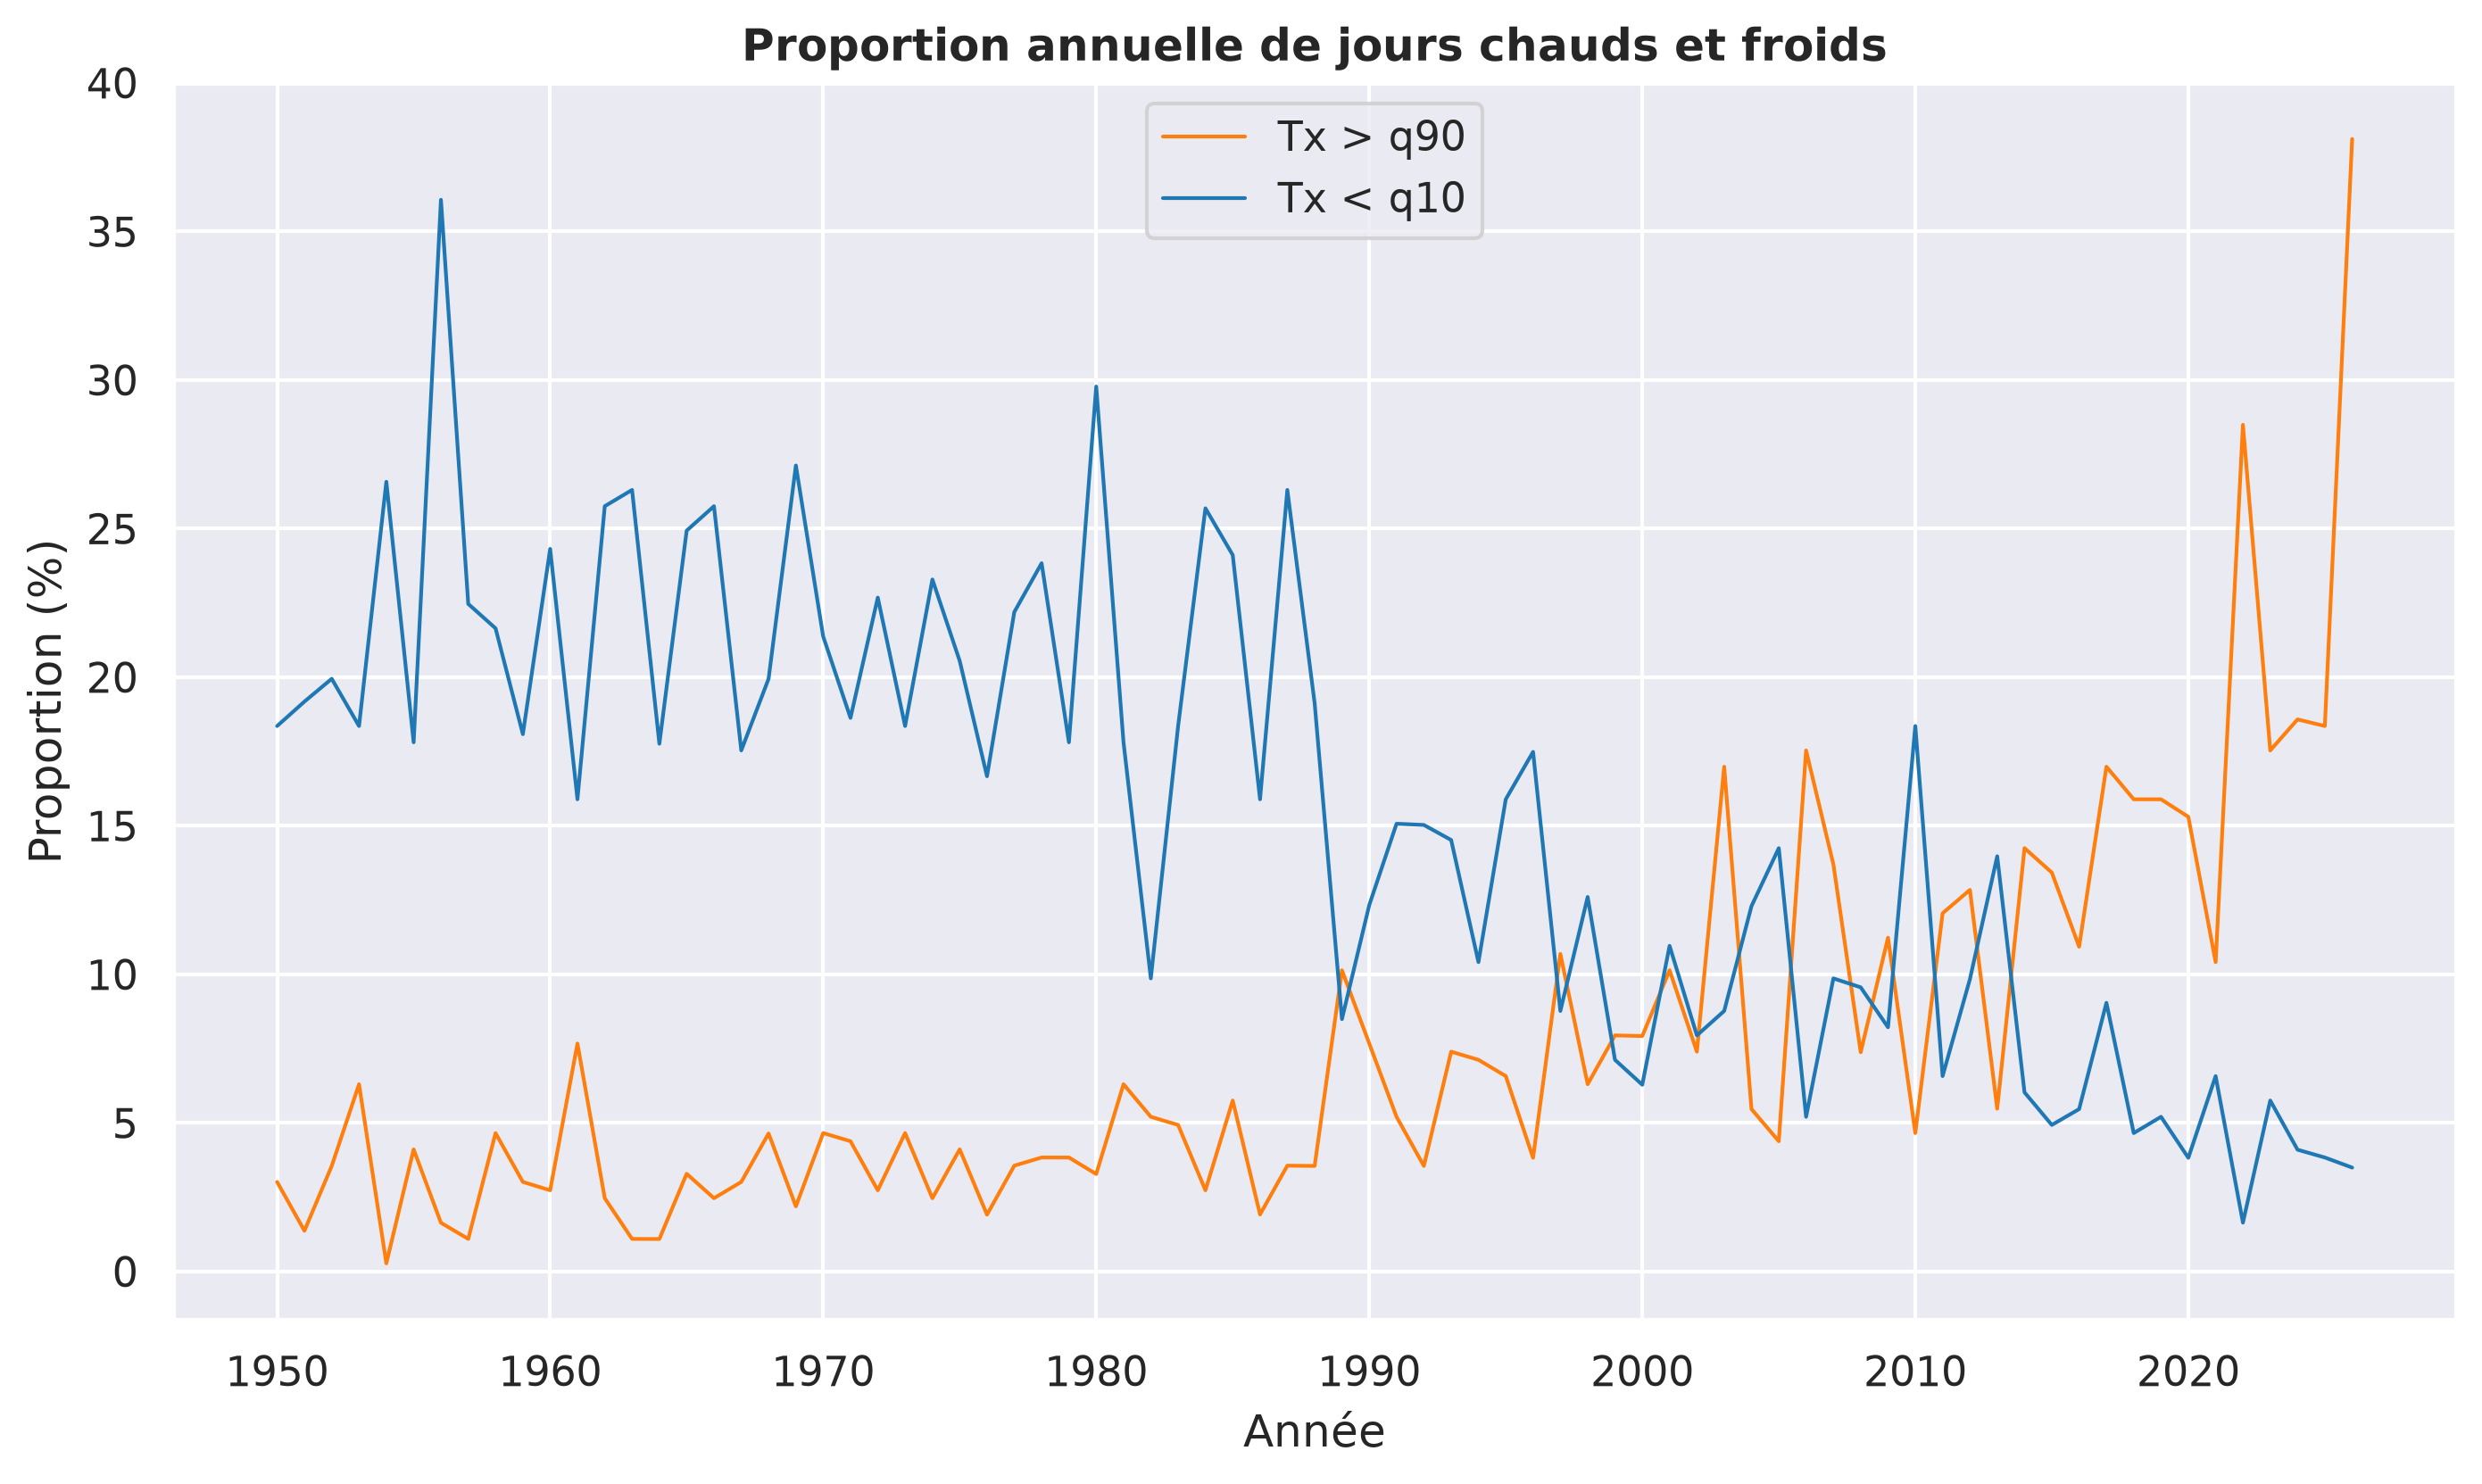

In [19]:
import seaborn as sns
import matplotlib.pyplot as plt


sns.set_theme(style="darkgrid")
plt.rcParams["figure.dpi"] = 300
plt.rcParams["figure.figsize"] = (11, 6)

plot_std_df = df_annual.filter(pl.col("station_id") == "13054001")

x = plot_std_df["year"].to_list()

fig, ax = plt.subplots()

ax.plot(
    x,
    plot_std_df["hot_pct"],
    linewidth=1.0,
    color="#FF7F0E",
    label="Tx > q90",
)

ax.plot(
    x,
    plot_std_df["cold_pct"],
    linewidth=1.0,
    color="#1F77B4",
    label="Tx < q10",
)

ax.set_title("Proportion annuelle de jours chauds et froids", fontweight="bold")
ax.set_xlabel("Année")
ax.set_ylabel("Proportion (%)")
ax.legend()

plt.show()

### Power BI 2026 export

In [ ]:
lf_obs_2026 = (
    lf_source
    .filter(
        pl.col("dataset_year") == 2026,
        pl.col("collection") == "quot",
        pl.col("period") == "latest",
        pl.col("department").is_in(selected_departments),
        pl.col("station_id").is_in(selected_station_ids),
        pl.col("obs_date").is_between(date(2026, 1, 1), date(2026, 10, 13)),
    )
    .select(
        "station_id",
        "station_name",
        "altitude",
        "latitude",
        "longitude",
        "obs_date",
        "tx",
    )
    .with_columns(
        pl.col("obs_date").dt.strftime(format="%m-%d").alias("clim_day"),
    )
)

In [ ]:
lf_normals_tx = (
    df_daily_normals
    .lazy()
    .select(
        "station_id",
        "clim_day",
        "tx_mean_smooth",
        "tx_std_smooth",
    )
)

In [ ]:
lf_dashboard_2026 = (
    lf_obs_2026
    .join(
        lf_normals_tx,
        on=["station_id", "clim_day"],
        how="inner",
    )
    .with_columns(
        (pl.col("tx") - pl.col("tx_mean_smooth")).alias("ano_tx"),
    )
    .with_columns(
        (pl.col("ano_tx") / pl.col("tx_std_smooth")).alias("z_tx"),
    )
    .filter(pl.col("z_tx").is_finite())
    .with_columns(
        pl.when(pl.col("z_tx") < -2)
        .then(pl.lit("1 - Très froid"))
        .when(pl.col("z_tx") < -1)
        .then(pl.lit("2 - Froid"))
        .when(pl.col("z_tx") < -0.4307273)
        .then(pl.lit("3 - Frais"))
        .when(pl.col("z_tx") <= 0.4307273)
        .then(pl.lit("4 - Normal"))
        .when(pl.col("z_tx") <= 1)
        .then(pl.lit("5 - Doux"))
        .when(pl.col("z_tx") <= 2)
        .then(pl.lit("6 - Chaud"))
        .otherwise(pl.lit("7 - Très chaud"))
        .alias("z_class_tx")
    )
)

### Test obs + clim day quantile for obs

#### First test

In [24]:
# # print(df_obs)

# print(df_daily_normals["residual_pool_tx"])

columns_select_normals_before = ["station_id", "clim_day"]
for param in params:
    columns_select_normals_before.extend([
        pl.col(f"{param}_mean_smooth"),
        pl.col(f"{param}_std_smooth"),
        pl.col(f"residual_pool_{param}"),
        # pl.col(f"{param}_lt_2sigma"),
        # pl.col(f"{param}_lt_1sigma"),
        # pl.col(f"{param}_gt_1sigma"),
        # pl.col(f"{param}_gt_2sigma"),
    ])

columns_select_obs_after = ["station_id", "station_name", "obs_date", "clim_day", "year", "month", "day"]
for param in params:
    columns_select_obs_after.extend([
        pl.col(param),
        pl.col(f"z_{param}"),
        # pl.col(f"quantile_{param}"),
        pl.col(f"{param}_mean_smooth"),
        pl.col(f"{param}_std_smooth"),
        pl.col(f"ano_{param}"),
        pl.col(f"residual_pool_{param}"),
    ])

expressions = []
z_class_expressions = []
for param in params:
    expressions.append((pl.col(param) - pl.col(f"{param}_mean_smooth")).alias(f"ano_{param}"))
    expressions.append(((pl.col(param) - pl.col(f"{param}_mean_smooth")) / pl.col(f"{param}_std_smooth")).alias(f"z_{param}"))

df_obs_phals = (
    df_obs
    .join(
        df_daily_normals.select(columns_select_normals_before),
        how="inner",
        on=["station_id", "clim_day"],
    )
    .with_columns(expressions)
    # .with_columns(
    #     tx_ecdf=pl.int_range(1, pl.count() + 1).sort_by(pl.arg_sort_by(""))
    # )
    .select(columns_select_obs_after)
    .sort("station_id", "obs_date")
)

print(df_obs_phals.shape)

(29506, 31)


In [ ]:
row_zero = df_obs_phals.row(0, named=True)
print(row_zero["tx"])
print(row_zero["ano_tx"])
# print(df_obs_phals.row(0, named=True))

pool_ser = (
    pl.DataFrame({
        "res_pool_plus_tx": row_zero["residual_pool_tx"] + [row_zero["ano_tx"]]
    })
).with_columns(
    tx_ecdf=pl.int_range(1, pl.count("res_pool_plus_tx") + 1).sort_by(pl.arg_sort_by("res_pool_plus_tx")) / pl.count("res_pool_plus_tx"),
)

with pl.Config(tbl_rows=500):
    print(pool_ser)

with pl.Config(tbl_rows=500):
    print(pool_ser.sort("tx_ecdf"))


-0.8
-5.204643785330747
{'station_id': '57168001', 'station_name': 'PHALSBOURG_SAPC', 'obs_date': datetime.date(1946, 1, 1), 'clim_day': '01-01', 'year': 1946, 'month': 1, 'day': 1, 'tn': -6.6, 'z_tn': -1.274720005026904, 'tn_mean_smooth': -0.3167807526088127, 'tn_std_smooth': 4.929097545039762, 'ano_tn': -6.2832192473911865, 'residual_pool_tn': [0.12210752246274381, -1.8778924775372563, -1.2778924775372562, -2.677892477537256, 1.9221075224627437, -11.077892477537256, 8.522107522462745, -1.9778924775372564, 2.522107522462744, -0.1778924775372562, -1.9778924775372564, 6.922107522462744, -2.777892477537256, 2.522107522462744, 1.9221075224627437, -1.6778924775372561, -9.477892477537255, 0.022107522462743806, 1.122107522462744, -7.877892477537256, 2.022107522462744, 7.222107522462744, 4.622107522462744, 3.022107522462744, 11.022107522462745, 5.722107522462744, 0.6221075224627438, -1.4778924775372562, 4.122107522462744, -0.07789247753725617, -1.46287818563606, -5.56287818563606, -3.86287818

#### Second test

In [35]:
lf_source = (
    pl.scan_parquet(
        PROCESSED_DAILY_DIR / "parameter_family=rr_t_vent",
        hive_partitioning=True,
        hive_schema={
            "dataset_year": pl.UInt16,
            "department": pl.String,
            "collection": pl.String,
            "period": pl.String,
        },
    )
)

lf_obs = (
    lf_source
    .filter(
        pl.col("collection") == "quot",
        pl.col("department").is_in(selected_departments),
        pl.col("station_id").is_in(selected_station_ids),
    )
    .select(
        "station_id",
        "station_name",
        "altitude",
        "latitude",
        "longitude",
        "obs_date",
        *(pl.col(param) for param in params),
    )
    .sort(
        "station_id",
        "obs_date",
    )
    .with_columns(
        pl.col("obs_date").dt.year().alias("year"),
        pl.col("obs_date").dt.month().alias("month"),
        pl.col("obs_date").dt.day().alias("day"),
        pl.col("obs_date").dt.strftime(format="%m-%d").alias("clim_day"),
    )
    .select(
        "station_id", "station_name", "altitude", "latitude", "longitude",
        "obs_date", "year", "month", "day", "clim_day",
        *(pl.col(param) for param in params),
    )
)

In [36]:
lf_normals = pl.scan_parquet(config.PROJECT_ROOT / "dump/daily_normals_1991_2020_20261030T223431Z.parquet")

In [37]:
lf_residuals = pl.scan_parquet(config.PROJECT_ROOT / "dump/reference_residuals_1991_2020_20261030T223431Z.parquet")

In [38]:
lf_enriched = (
    lf_obs
    .join(
        lf_normals.select("station_id", "clim_day", "tx_mean_smooth", "tx_std_smooth"),
        on=["station_id", "clim_day"],
        how="left",
    )
    .with_columns(
        (pl.col("tx") - pl.col("tx_mean_smooth")).alias("ano_tx"),
    )
    .with_columns(
        (pl.col("ano_tx") / pl.col("tx_std_smooth")).alias("z_tx"),
    )
    .with_columns(
        pl.when(pl.col("z_tx") < -2)
        .then(pl.lit("1 - Très froid"))
        .when(pl.col("z_tx") < -1)
        .then(pl.lit("2 - Froid"))
        .when(pl.col("z_tx") < -0.4307273)
        .then(pl.lit("3 - Frais"))
        .when(pl.col("z_tx") <= 0.4307273)
        .then(pl.lit("4 - Normal"))
        .when(pl.col("z_tx") <= 1)
        .then(pl.lit("5 - Doux"))
        .when(pl.col("z_tx") <= 2)
        .then(pl.lit("6 - Chaud"))
        .otherwise(pl.lit("7 - Très chaud"))
        .alias("z_class_tx_label")
    )
    .with_columns(
        pl.when(pl.col("z_tx") < -2)
        .then(pl.lit("1 - z < 2"))
        .when(pl.col("z_tx") < -1)
        .then(pl.lit("2 - -2 <= z < -1"))
        .when(pl.col("z_tx") < -0.4307273)
        .then(pl.lit("3 - -1 <= z < -0,4307"))
        .when(pl.col("z_tx") <= 0.4307273)
        .then(pl.lit("4 - -0,4307 <= z <= 0,4307"))
        .when(pl.col("z_tx") <= 1)
        .then(pl.lit("5 - 0,4307 < z <= 1"))
        .when(pl.col("z_tx") <= 2)
        .then(pl.lit("6 - 1 < z <= 2"))
        .otherwise(pl.lit("7 - z > 2"))
        .alias("z_class_tx")
    )
    .sort("station_id", "obs_date")
)

In [39]:
reference_residuals_df = lf_residuals.collect(engine="streaming")

In [ ]:
res_test_paris = reference_residuals_df.filter(
    pl.col("station_id") == "75114001",
    pl.col("clim_day").str.starts_with("10"),
)
print(res_test_paris)

shape: (31, 6)
┌────────────┬──────────┬──────────────────┬──────────────────┬──────────────────┬─────────────────┐
│ station_id ┆ clim_day ┆ residual_list_tn ┆ residual_list_tx ┆ residual_list_tn ┆ residual_list_t │
│ ---        ┆ ---      ┆ ---              ┆ ---              ┆ txm              ┆ ampli           │
│ str        ┆ str      ┆ list[f64]        ┆ list[f64]        ┆ ---              ┆ ---             │
│            ┆          ┆                  ┆                  ┆ list[f64]        ┆ list[f64]       │
╞════════════╪══════════╪══════════════════╪══════════════════╪══════════════════╪═════════════════╡
│ 75114001   ┆ 10-01    ┆ [-1.496484,      ┆ [-3.564573,      ┆ [-2.505259,      ┆ [-2.068089,     │
│            ┆          ┆ -0.996484, …     ┆ -1.264573, …     ┆ -1.105259, …     ┆ -0.268089, …    │
│            ┆          ┆ 1.303…           ┆ -2.46…           ┆ -0.60…           ┆ -3.76…          │
│ 75114001   ┆ 10-02    ┆ [-1.000216,      ┆ [-1.202693,      ┆ [-1.076156, 

In [40]:
def empirical_percentiles(
        reference_residuals: np.ndarray,
        observed_residuals: np.ndarray,
) -> np.ndarray:
    ref = np.asarray(reference_residuals, dtype=float)
    obs = np.asarray(observed_residuals, dtype=float)

    ref = np.sort(ref[np.isfinite(ref)])

    result = np.full(obs.shape, np.nan, dtype=float)

    if len(ref) == 0:
        return result
    
    valid = np.isfinite(obs)

    result[valid] = (
        np.searchsorted(
            ref,
            obs[valid],
            side="right",
        )
        / len(ref)
    )

    return result

In [48]:
res_test_paris = reference_residuals_df.filter(
    pl.col("station_id") == "75114001",
    pl.col("clim_day").str.starts_with("10"),
)
print(res_test_paris.filter(pl.col("clim_day") == "10-01")["residual_list_tx"].item())
print(empirical_percentiles(
    res_test_paris.filter(pl.col("clim_day") == "10-01")["residual_list_tx"].item(),
    [1.94],
))
print(empirical_percentiles(
    res_test_paris.filter(pl.col("clim_day") == "10-31")["residual_list_tx"].item(),
    [7.09],
))
print(res_test_paris)

shape: (30,)
Series: '' [f64]
[
	-3.564573
	-1.264573
	-3.564573
	0.235427
	2.335427
	…
	-0.364573
	-2.864573
	-2.964573
	2.535427
	-2.464573
]
[0.73333333]
[0.96666667]
shape: (31, 6)
┌────────────┬──────────┬──────────────────┬──────────────────┬──────────────────┬─────────────────┐
│ station_id ┆ clim_day ┆ residual_list_tn ┆ residual_list_tx ┆ residual_list_tn ┆ residual_list_t │
│ ---        ┆ ---      ┆ ---              ┆ ---              ┆ txm              ┆ ampli           │
│ str        ┆ str      ┆ list[f64]        ┆ list[f64]        ┆ ---              ┆ ---             │
│            ┆          ┆                  ┆                  ┆ list[f64]        ┆ list[f64]       │
╞════════════╪══════════╪══════════════════╪══════════════════╪══════════════════╪═════════════════╡
│ 75114001   ┆ 10-01    ┆ [-1.496484,      ┆ [-3.564573,      ┆ [-2.505259,      ┆ [-2.068089,     │
│            ┆          ┆ -0.996484, …     ┆ -1.264573, …     ┆ -1.105259, …     ┆ -0.268089, …    │
│      

In [41]:
import sys


lf_obs_2026 = (
    lf_enriched
    .filter(
        pl.col("obs_date").dt.year() >= 2026,
        pl.col("z_tx").is_finite(),
    )
)

# df_obs_2026 = lf_obs_2026.collect(engine="streaming")

# Grouper les obs par station-JC pour calculer np.searchsorted

lf_obs_residuals = (
    lf_obs_2026
    .group_by(
        "station_id", "clim_day",
        maintain_order=True,
    )
    .agg(
        ano_tx_list=pl.col("ano_tx"),
        obs_date_list=pl.col("obs_date"),
    )
)

observed_residuals_df = (
    normals_grid
    .lazy()
    .join(
        lf_obs_residuals,
        how="left",
        on=["station_id", "clim_day"]
    )
    .collect(engine="streaming")
)

print(observed_residuals_df.shape)

observations_by_key = {
    (row["station_id"], row["clim_day"]): (
        row["obs_date_list"] or [],
        row["ano_tx_list"] or [],
    )
    for row in observed_residuals_df.iter_rows(named=True)
}

dfs_percentiles = []
for station_id in selected_station_ids:
    print(f"station_id: {station_id}")
    station_reference = (
        reference_residuals_df
        .filter(pl.col("station_id") == station_id)
        .sort("clim_day")
    )

    assert station_reference["clim_day"].to_list() == clim_days["clim_day"].to_list()

    pools = compute_circular_residual_dist(
        (
            station_reference
            .select("residual_list_tx")
            .to_series()
        ),
        window_size=15,
    )

    for clim_day in clim_days.iter_rows(named=True):
        key = (station_id, clim_day["clim_day"])
        observations = observations_by_key.get(key)

        if observations is None:
            continue

        obs_dates, obs_residuals = observations

        # reference_residuals = pools[clim_day["clim_day_idx"]]
        # observed_df = (
        #     observed_residuals_df
        #     .filter(
        #         pl.col("station_id") == station_id,
        #         pl.col("clim_day") == clim_day["clim_day"],
        #     )
        # )
        # if observed_df.height == 0:
        #     continue

        # observed_residuals = observed_df.select("ano_tx_list").item()
        percentiles = empirical_percentiles(
            pools[clim_day["clim_day_idx"]],  # reference residuals
            obs_residuals,
        )
        # if station_id is None or obs_dates is None or percentiles is None:
        #     print(f"""
        #         station_id: {station_id},
        #         obs_dates: {obs_dates},
        #         percentiles: {percentiles}
        #     """)
        df_percentiles = (
            pl.DataFrame({
                "station_id": station_id,
                "obs_date": obs_dates,
                "tx_ecdf": percentiles,
            })
        )
        dfs_percentiles.append(df_percentiles)

# df_enriched = (
#     df_obs_2026
#     .join(
#         pl.concat(dfs_percentiles, how="vertical"),
#         how="left",
#         on=["station_id", "obs_date"],
#     )
# )

# df_enriched = (
#     lf_obs_2026
#     .join(
#         pl.concat(dfs_percentiles, how="vertical").lazy(),
#         how="left",
#         on=["station_id", "obs_date"],
#     )
#     .head(100)
#     .collect(engine="streaming")
# )

# print(df_enriched)

(47946, 8)
station_id: 01089001
station_id: 02320001
station_id: 03060001
station_id: 03204001
station_id: 05046001
station_id: 06029001
station_id: 06088001
station_id: 07159001
station_id: 07265001
station_id: 10057001
station_id: 10130001
station_id: 10323001
station_id: 11012001
station_id: 11069001
station_id: 13047001
station_id: 13054001
station_id: 13103001
station_id: 14137001
station_id: 14578001
station_id: 16089001
station_id: 17323001
station_id: 17415003
station_id: 18033001
station_id: 18092001
station_id: 18242001
station_id: 19275001
station_id: 20004002
station_id: 20041001
station_id: 20148001
station_id: 21154001
station_id: 21473001
station_id: 21527001
station_id: 22168001
station_id: 23067001
station_id: 25021001
station_id: 25056001
station_id: 25320001
station_id: 25462001
station_id: 26168001
station_id: 26198001
station_id: 26307001
station_id: 26330001
station_id: 28070001
station_id: 28322001
station_id: 29075001
station_id: 29082001
station_id: 29120001
st

In [42]:
ts = utc_now_iso()

lf_obs_2026_ecdf = (
    lf_obs_2026
    .join(
        pl.concat(dfs_percentiles, how="vertical").lazy(),
        how="left",
        on=["station_id", "obs_date"],
    )
    .with_columns(
        pl.when(pl.col("tx_ecdf") < 0.022750)
        .then(pl.lit("1 - Très froid"))
        .when(pl.col("tx_ecdf") < 0.158655)
        .then(pl.lit("2 - Froid"))
        .when(pl.col("tx_ecdf") < 0.333333)
        .then(pl.lit("3 - Frais"))
        .when(pl.col("tx_ecdf") <= 0.666667)
        .then(pl.lit("4 - Normal"))
        .when(pl.col("tx_ecdf") <= 0.841345)
        .then(pl.lit("5 - Doux"))
        .when(pl.col("tx_ecdf") <= 0.977250)
        .then(pl.lit("6 - Chaud"))        
        .otherwise(pl.lit("7 - Très chaud"))
        .alias("tx_ecdf_class_label")
    )
    .with_columns(
        pl.when(pl.col("tx_ecdf") < 0.022750)
        .then(pl.lit("1 - Tx < Q2"))
        .when(pl.col("tx_ecdf") < 0.158655)
        .then(pl.lit("2 - Q2 <= Tx < Q16"))
        .when(pl.col("tx_ecdf") < 0.333333)
        .then(pl.lit("3 - Q16 <= Tx < Q33"))
        .when(pl.col("tx_ecdf") <= 0.666667)
        .then(pl.lit("4 - Q33 <= Tx <= Q67"))
        .when(pl.col("tx_ecdf") <= 0.841345)
        .then(pl.lit("5 - Q67 < Tx <= Q84"))
        .when(pl.col("tx_ecdf") <= 0.977250)
        .then(pl.lit("6 - Q84 < Tx <= Q98"))        
        .otherwise(pl.lit("7 - Tx > Q98"))
        .alias("tx_ecdf_class")
    )
    .select(
        "station_id", "station_name",
        "altitude", "latitude", "longitude",
        "obs_date",
        "tx", "ano_tx", "tx_mean_smooth", "tx_std_smooth",
        "z_tx", "tx_ecdf", "z_class_tx_label", "tx_ecdf_class_label", "z_class_tx", "tx_ecdf_class",
    )
)

# df_enriched = lf_enriched_ecdf.collect(engine="streaming")

(
    lf_obs_2026_ecdf
    .sort("station_id", "obs_date")
    .sink_parquet(
        config.PROJECT_ROOT / "dump" / f"obs_test_tx_ecdf_{ts}.parquet",
        compression="zstd",
    )
)


lf_print = (
    lf_obs_2026_ecdf
    # .sort("station_id", "obs_date")
    .filter(
        # pl.col("station_id").str.starts_with("79191005"),
        pl.col("tx_ecdf_class").str.slice(0, 1).is_in(["1", "7"]),
    )
    .sort("obs_date", descending=True)
)

lf_print.sink_csv(config.PROJECT_ROOT / "dump" / f"obs_test_tx_ecdf_{ts}.csv", separator=";", decimal_comma=True)

df_print = (
    lf_print
    .head(800)
    .collect(engine="streaming")
)

with pl.Config(tbl_cols=20, tbl_rows=800, tbl_width_chars=400):
    print(df_print)

shape: (800, 16)
┌────────────┬────────────────────────────────┬──────────┬───────────┬───────────┬────────────┬──────┬───────────┬────────────────┬───────────────┬──────────┬──────────┬──────────────────┬─────────────────────┬────────────────┬───────────────┐
│ station_id ┆ station_name                   ┆ altitude ┆ latitude  ┆ longitude ┆ obs_date   ┆ tx   ┆ ano_tx    ┆ tx_mean_smooth ┆ tx_std_smooth ┆ z_tx     ┆ tx_ecdf  ┆ z_class_tx_label ┆ tx_ecdf_class_label ┆ z_class_tx     ┆ tx_ecdf_class │
│ ---        ┆ ---                            ┆ ---      ┆ ---       ┆ ---       ┆ ---        ┆ ---  ┆ ---       ┆ ---            ┆ ---           ┆ ---      ┆ ---      ┆ ---              ┆ ---                 ┆ ---            ┆ ---           │
│ str        ┆ str                            ┆ i16      ┆ f64       ┆ f64       ┆ date       ┆ f64  ┆ f64       ┆ f64            ┆ f64           ┆ f64      ┆ f64      ┆ str              ┆ str                 ┆ str            ┆ str           │
╞══════

##### Exploring z-score vs quantiles

In [34]:
print(
    lf_obs_2026_ecdf
    .group_by("z_class_tx")
    .agg(
        pl.len().alias("len"),
    )
    .with_columns(
        pct=pl.col("len") / pl.col("len").sum(),
    )
    .sort("z_class_tx")
    .collect(engine="streaming")
)

print(
    lf_obs_2026_ecdf
    .group_by("tx_ecdf_class")
    .agg(
        pl.len().alias("len"),
    )
    .with_columns(
        pct=pl.col("len") / pl.col("len").sum(),
    )
    .sort("tx_ecdf_class")
    .collect(engine="streaming")
)

with pl.Config(tbl_rows=50):
    print(
        lf_obs_2026_ecdf
        .group_by("z_class_tx", "tx_ecdf_class")
        .agg(
            pl.len().alias("len"),
        )
        .with_columns(
            pct=pl.col("len") / pl.col("len").sum(),            
        )
        .sort("z_class_tx", "tx_ecdf_class")
        .collect(engine="streaming")
    )

shape: (7, 3)
┌────────────────┬───────┬──────────┐
│ z_class_tx     ┆ len   ┆ pct      │
│ ---            ┆ ---   ┆ ---      │
│ str            ┆ u32   ┆ f64      │
╞════════════════╪═══════╪══════════╡
│ 1 - Très froid ┆ 364   ┆ 0.004271 │
│ 2 - Froid      ┆ 4531  ┆ 0.053159 │
│ 3 - Frais      ┆ 9661  ┆ 0.113345 │
│ 4 - Normal     ┆ 24598 ┆ 0.28859  │
│ 5 - Doux       ┆ 17740 ┆ 0.20813  │
│ 6 - Chaud      ┆ 20311 ┆ 0.238294 │
│ 7 - Très chaud ┆ 8030  ┆ 0.09421  │
└────────────────┴───────┴──────────┘
shape: (7, 3)
┌──────────────────────┬───────┬──────────┐
│ tx_ecdf_class        ┆ len   ┆ pct      │
│ ---                  ┆ ---   ┆ ---      │
│ str                  ┆ u32   ┆ f64      │
╞══════════════════════╪═══════╪══════════╡
│ 1 - Tx < Q2          ┆ 363   ┆ 0.004259 │
│ 2 - Q2 <= Tx < Q16   ┆ 4384  ┆ 0.051434 │
│ 3 - Q16 <= Tx < Q33  ┆ 8989  ┆ 0.105461 │
│ 4 - Q33 <= Tx <= Q67 ┆ 25362 ┆ 0.297554 │
│ 5 - Q67 <= Tx < Q84  ┆ 17994 ┆ 0.21111  │
│ 6 - Q84 <= Tx < Q98  ┆ 20067 ┆ 0.235

#### 131 mean

In [52]:
panel_aggregates = []
columns_select_panel = [
    "station_id", "station_name", "obs_date",
    pl.col("obs_date").dt.year().alias("year"),
    pl.col("obs_date").dt.month().alias("month"),
    pl.col("obs_date").dt.day().alias("day"),
    pl.col("obs_date").dt.strftime(format="%m-%d").alias("clim_day"),
]
for param in params:
    panel_aggregates.extend([
        pl.col(param).mean().alias(f"{param}"),
        pl.col(param).count().alias(f"n_stations_{param}"),
    ])
    columns_select_panel.extend([
        pl.col(f"{param}"),
        pl.col(f"n_stations_{param}"),
    ])

lf_panel_daily = (
    lf_obs
    .filter(
        pl.col("station_id").is_in(selected_station_ids),
        pl.col("obs_date") >= date(1950, 1, 1),
    )
    .group_by("obs_date")
    .agg(panel_aggregates)
    .with_columns(
        pl.lit("panel_131").alias("station_id"),
        pl.lit("Panel 131").alias("station_name"),
    )
    .select(columns_select_panel)
    .sort("obs_date")
)

In [56]:
df_panel_daily_normals = compute_df_daily_normals_lf(lf_panel_daily, ["panel_131"])

In [58]:
with pl.Config(tbl_rows=400, tbl_cols=40, tbl_width_chars=600):
    print(df_panel_daily_normals)

shape: (366, 133)
┌────────────┬──────────────┬───────┬─────┬──────────┬──────────┬─────────────┬────────────┬────────────────┬───────────────┬────────────┬────────────┬───────────┬───────────┬───────────────┬───────────────┬────────────┬────────────┬────────────────┬────────────────┬───┬────────────────┬────────────────┬────────────────┬────────────────┬────────────────┬────────────────┬────────────────┬────────────────┬────────────────┬───────────────┬───────────────┬───────────────┬───────────────┬───────────────┬───────────────┬───────────────┬───────────────┬───────────────┬───────────────┬───────────────┐
│ station_id ┆ station_name ┆ month ┆ day ┆ clim_day ┆ tn_n_obs ┆ tn_mean_raw ┆ tn_std_raw ┆ tn_mean_smooth ┆ tn_std_smooth ┆ tn_min_raw ┆ tn_q0_res  ┆ tn_q1_raw ┆ tn_q1_res ┆ tn_q2_275_raw ┆ tn_q2_275_res ┆ tn_q10_raw ┆ tn_q10_res ┆ tn_q15_8655_ra ┆ tn_q15_8655_re ┆ … ┆ tampli_q10_res ┆ tampli_q15_865 ┆ tampli_q15_865 ┆ tampli_q25_raw ┆ tampli_q25_res ┆ tampli_q50_raw ┆ tampli_

In [60]:
ts = utc_now_iso()
df_panel_daily_normals.write_csv(config.PROJECT_ROOT / "dump" / f"daily_normals_1991_2020_{ts}.csv", separator=";", decimal_comma=True)

In [25]:
df_panel_daily = lf_panel_daily.collect(
    engine="streaming",
)

In [61]:
ts = utc_now_iso()
lf_panel_daily.sink_parquet(
    config.PROJECT_ROOT / "dump" / f"obs_panel_131_{ts}_1950_.parquet",
    compression="zstd",
)

In [30]:
with pl.Config(tbl_rows=400, tbl_width_chars=400):
    # print(df_panel_daily)
    # print(df_panel_daily.sort("tx_panel", descending=True))
    print(df_panel_daily.sort("n_stations_tx", descending=False))

shape: (28_045, 3)
┌────────────┬───────────┬───────────────┐
│ obs_date   ┆ tx_panel  ┆ n_stations_tx │
│ ---        ┆ ---       ┆ ---           │
│ date       ┆ f64       ┆ u32           │
╞════════════╪═══════════╪═══════════════╡
│ 1950-07-02 ┆ 29.183594 ┆ 128           │
│ 1950-07-23 ┆ 25.934375 ┆ 128           │
│ 1950-08-13 ┆ 25.942969 ┆ 128           │
│ 1950-08-14 ┆ 25.398438 ┆ 128           │
│ 1950-08-15 ┆ 25.775    ┆ 128           │
│ 1950-09-03 ┆ 19.215625 ┆ 128           │
│ 1950-09-10 ┆ 24.182812 ┆ 128           │
│ 1950-09-17 ┆ 20.594531 ┆ 128           │
│ 1950-09-24 ┆ 20.898437 ┆ 128           │
│ 1950-11-05 ┆ 8.567188  ┆ 128           │
│ 1950-11-11 ┆ 13.7      ┆ 128           │
│ 1950-11-12 ┆ 12.724219 ┆ 128           │
│ 1954-04-01 ┆ 13.002344 ┆ 128           │
│ 1954-04-02 ┆ 14.816406 ┆ 128           │
│ 1954-04-03 ┆ 15.334375 ┆ 128           │
│ 1960-12-17 ┆ 3.305469  ┆ 128           │
│ 2018-11-18 ┆ 9.945312  ┆ 128           │
│ 2018-11-19 ┆ 6.477344  ┆ 128     

#### Second test panel 131

In [53]:
lf_source_panel = (
    pl.scan_parquet(config.PROJECT_ROOT / "dump" / f"obs_panel_131_20261030T160909Z_1950_.parquet")
)

lf_obs_panel = (
    lf_source_panel
    .filter(
        pl.col("station_id").is_in(["panel_131"]),
    )
    .select(
        columns_select_panel
    )
    .sort(
        "station_id",
        "obs_date",
    )
)

In [54]:
lf_normals_panel = pl.scan_parquet(config.PROJECT_ROOT / "dump" / "daily_normals_1991_2020_20261030T153945Z.parquet")

In [55]:
lf_residuals_panel = pl.scan_parquet(config.PROJECT_ROOT / "dump" / "reference_residuals_1991_2020_20261030T153945Z.parquet")

In [56]:
lf_enriched_panel = (
    lf_obs_panel
    .join(
        lf_normals_panel.select("station_id", "clim_day", "tx_mean_smooth", "tx_std_smooth"),
        on=["station_id", "clim_day"],
        how="left",
    )
    .with_columns(
        (pl.col("tx") - pl.col("tx_mean_smooth")).alias("ano_tx"),
    )
    .with_columns(
        (pl.col("ano_tx") / pl.col("tx_std_smooth")).alias("z_tx"),
    )
    .with_columns(
        pl.when(pl.col("z_tx") < -2)
        .then(pl.lit("1 - Très froid"))
        .when(pl.col("z_tx") < -1)
        .then(pl.lit("2 - Froid"))
        .when(pl.col("z_tx") < -0.4307273)
        .then(pl.lit("3 - Frais"))
        .when(pl.col("z_tx") <= 0.4307273)
        .then(pl.lit("4 - Normal"))
        .when(pl.col("z_tx") <= 1)
        .then(pl.lit("5 - Doux"))
        .when(pl.col("z_tx") <= 2)
        .then(pl.lit("6 - Chaud"))
        .otherwise(pl.lit("7 - Très chaud"))
        .alias("z_class_tx_label")
    )
    .with_columns(
        pl.when(pl.col("z_tx") < -2)
        .then(pl.lit("1 - z < 2"))
        .when(pl.col("z_tx") < -1)
        .then(pl.lit("2 - -2 <= z < -1"))
        .when(pl.col("z_tx") < -0.4307273)
        .then(pl.lit("3 - -1 <= z < -0,4307"))
        .when(pl.col("z_tx") <= 0.4307273)
        .then(pl.lit("4 - -0,4307 <= z <= 0,4307"))
        .when(pl.col("z_tx") <= 1)
        .then(pl.lit("5 - 0,4307 < z <= 1"))
        .when(pl.col("z_tx") <= 2)
        .then(pl.lit("6 - 1 < z <= 2"))
        .otherwise(pl.lit("7 - z > 2"))
        .alias("z_class_tx")
    )
    .sort("station_id", "obs_date")
)

In [57]:
reference_residuals_df_panel = lf_residuals_panel.collect(engine="streaming")

In [90]:
print(reference_residuals_df_panel)

shape: (366, 6)
┌────────────┬──────────┬──────────────────┬──────────────────┬──────────────────┬─────────────────┐
│ station_id ┆ clim_day ┆ residual_list_tn ┆ residual_list_tx ┆ residual_list_tn ┆ residual_list_t │
│ ---        ┆ ---      ┆ ---              ┆ ---              ┆ txm              ┆ ampli           │
│ str        ┆ str      ┆ list[f64]        ┆ list[f64]        ┆ ---              ┆ ---             │
│            ┆          ┆                  ┆                  ┆ list[f64]        ┆ list[f64]       │
╞════════════╪══════════╪══════════════════╪══════════════════╪══════════════════╪═════════════════╡
│ panel_131  ┆ 01-01    ┆ [3.163324,       ┆ [4.753062,       ┆ [3.967236,       ┆ [1.58974,       │
│            ┆          ┆ -2.900035, …     ┆ -3.01106, …      ┆ -2.958718, …     ┆ -0.111023, …    │
│            ┆          ┆ -1.571…          ┆ 2.39046…         ┆ 0.4153…          ┆ 3.96225…        │
│ panel_131  ┆ 01-02    ┆ [4.950157,       ┆ [3.546144,       ┆ [4.255279, 

In [58]:
import sys


lf_obs_2026_panel = (
    lf_enriched_panel
    .filter(
        pl.col("obs_date").dt.year() >= 2026,
        pl.col("z_tx").is_finite(),
    )
)

# df_obs_2026 = lf_obs_2026.collect(engine="streaming")

# Grouper les obs par station-JC pour calculer np.searchsorted

lf_obs_residuals_panel = (
    lf_obs_2026_panel
    .group_by(
        "station_id", "clim_day",
        maintain_order=True,
    )
    .agg(
        ano_tx_list=pl.col("ano_tx"),
        obs_date_list=pl.col("obs_date"),
    )
)

normals_grid_panel = (
    clim_days
    .join(
        pl.DataFrame({"station_id": ["panel_131"]}),
        how="cross",
    )
    .sort("station_id", "clim_day")
)

observed_residuals_df_panel = (
    normals_grid_panel
    .lazy()
    .join(
        lf_obs_residuals_panel,
        how="left",
        on=["station_id", "clim_day"]
    )
    .collect(engine="streaming")
)

print(observed_residuals_df_panel.shape)
print(observed_residuals_df_panel)

observations_by_key_panel = {
    (row["station_id"], row["clim_day"]): (
        row["obs_date_list"] or [],
        row["ano_tx_list"] or [],
    )
    for row in observed_residuals_df_panel.iter_rows(named=True)
}

print(observations_by_key_panel)

dfs_percentiles_panel = []
for station_id in ["panel_131"]:
    print(f"station_id: {station_id}")
    station_reference = (
        reference_residuals_df_panel
        .filter(pl.col("station_id") == station_id)
        .sort("clim_day")
    )

    assert station_reference["clim_day"].to_list() == clim_days["clim_day"].to_list()

    print(f"station_reference: {station_reference}")

    pools = compute_circular_residual_dist(
        (
            station_reference
            .select("residual_list_tx")
            .to_series()
        ),
        window_size=15,
    )

    for clim_day in clim_days.iter_rows(named=True):
        key = (station_id, clim_day["clim_day"])
        observations = observations_by_key_panel.get(key)

        if observations is None:
            continue

        obs_dates, obs_residuals = observations

        # reference_residuals = pools[clim_day["clim_day_idx"]]
        # observed_df = (
        #     observed_residuals_df
        #     .filter(
        #         pl.col("station_id") == station_id,
        #         pl.col("clim_day") == clim_day["clim_day"],
        #     )
        # )
        # if observed_df.height == 0:
        #     continue

        # observed_residuals = observed_df.select("ano_tx_list").item()
        percentiles = empirical_percentiles(
            pools[clim_day["clim_day_idx"]],  # reference residuals
            obs_residuals,
        )
        # if station_id is None or obs_dates is None or percentiles is None:
        #     print(f"""
        #         station_id: {station_id},
        #         obs_dates: {obs_dates},
        #         percentiles: {percentiles}
        #     """)
        print(f"station_id: {station_id}")
        print(f"obs_date: {obs_dates}")
        print(f"tx_ecdf: {percentiles}")
        df_percentiles = (
            pl.DataFrame({
                "station_id": station_id,
                "obs_date": obs_dates,
                "tx_ecdf": percentiles,
            })
        )
        dfs_percentiles_panel.append(df_percentiles)

(366, 8)
shape: (366, 8)
┌──────────────┬────────────┬──────────┬───────┬─────┬────────────┬─────────────┬───────────────┐
│ clim_day_idx ┆ date       ┆ clim_day ┆ month ┆ day ┆ station_id ┆ ano_tx_list ┆ obs_date_list │
│ ---          ┆ ---        ┆ ---      ┆ ---   ┆ --- ┆ ---        ┆ ---         ┆ ---           │
│ u32          ┆ date       ┆ str      ┆ i8    ┆ i8  ┆ str        ┆ list[f64]   ┆ list[date]    │
╞══════════════╪════════════╪══════════╪═══════╪═════╪════════════╪═════════════╪═══════════════╡
│ 167          ┆ 2000-06-16 ┆ 06-16    ┆ 6     ┆ 16  ┆ panel_131  ┆ [4.828133]  ┆ [2026-06-16]  │
│ 176          ┆ 2000-06-25 ┆ 06-25    ┆ 6     ┆ 25  ┆ panel_131  ┆ [12.207471] ┆ [2026-06-25]  │
│ 180          ┆ 2000-06-29 ┆ 06-29    ┆ 6     ┆ 29  ┆ panel_131  ┆ [3.947177]  ┆ [2026-06-29]  │
│ 162          ┆ 2000-06-11 ┆ 06-11    ┆ 6     ┆ 11  ┆ panel_131  ┆ [-1.60311]  ┆ [2026-06-11]  │
│ 165          ┆ 2000-06-14 ┆ 06-14    ┆ 6     ┆ 14  ┆ panel_131  ┆ [5.158747]  ┆ [2026-06-14

In [66]:
ts = utc_now_iso()

lf_obs_2026_ecdf_panel = (
    lf_obs_2026_panel
    .join(
        pl.concat(dfs_percentiles_panel, how="vertical").lazy(),
        how="left",
        on=["station_id", "obs_date"],
    )
    .with_columns(
        pl.when(pl.col("tx_ecdf") < 0.022750)
        .then(pl.lit("1 - Très froid"))
        .when(pl.col("tx_ecdf") < 0.158655)
        .then(pl.lit("2 - Froid"))
        .when(pl.col("tx_ecdf") < 0.333333)
        .then(pl.lit("3 - Frais"))
        .when(pl.col("tx_ecdf") <= 0.666667)
        .then(pl.lit("4 - Normal"))
        .when(pl.col("tx_ecdf") <= 0.841345)
        .then(pl.lit("5 - Doux"))
        .when(pl.col("tx_ecdf") <= 0.977250)
        .then(pl.lit("6 - Chaud"))        
        .otherwise(pl.lit("7 - Très chaud"))
        .alias("tx_ecdf_class_label")
    )
    .with_columns(
        pl.when(pl.col("tx_ecdf") < 0.022750)
        .then(pl.lit("1 - Tx < Q2"))
        .when(pl.col("tx_ecdf") < 0.158655)
        .then(pl.lit("2 - Q2 <= Tx < Q16"))
        .when(pl.col("tx_ecdf") < 0.333333)
        .then(pl.lit("3 - Q16 <= Tx < Q33"))
        .when(pl.col("tx_ecdf") <= 0.666667)
        .then(pl.lit("4 - Q33 <= Tx <= Q67"))
        .when(pl.col("tx_ecdf") <= 0.841345)
        .then(pl.lit("5 - Q67 < Tx <= Q84"))
        .when(pl.col("tx_ecdf") <= 0.977250)
        .then(pl.lit("6 - Q84 < Tx <= Q98"))        
        .otherwise(pl.lit("7 - Tx > Q98"))
        .alias("tx_ecdf_class")
    )
    .select(
        "station_id", "station_name",
        "obs_date",
        "tx", "ano_tx", "tx_mean_smooth", "tx_std_smooth", "z_tx", "tx_ecdf", "z_class_tx", "tx_ecdf_class",
    )
)

(
    lf_obs_2026_ecdf_panel
    .sort("station_id", "obs_date")
    .sink_parquet(
        config.PROJECT_ROOT / "dump" / f"obs_test_tx_ecdf_panel_131_{ts}.parquet",
        compression="zstd",
    )
)


# lf_print_panel = (
#     lf_obs_2026_ecdf_panel
#     .filter(
#         pl.col("tx_ecdf") <= 0.02,
#     )
#     .sort("obs_date", descending=True)
# )

# lf_print_panel.sink_csv(config.PROJECT_ROOT / "dump" / f"obs_test_tx_ecdf_panel_131_{ts}.csv", separator=";", decimal_comma=True)

# df_print_panel = (
#     lf_print_panel
#     .head(800)
#     .collect(engine="streaming")
# )

df_obs_2026_ecdf_panel = (
    lf_obs_2026_ecdf_panel
    .sort("obs_date")
    .collect()
)

lf_obs_2026_ecdf_panel.sink_csv(config.PROJECT_ROOT / "dump" / f"obs_test_tx_ecdf_panel_131_{ts}.csv", separator=";", decimal_comma=True)

with pl.Config(tbl_cols=20, tbl_rows=800, tbl_width_chars=400):
    print(df_obs_2026_ecdf_panel)

shape: (286, 11)
┌────────────┬──────────────┬────────────┬───────────┬───────────┬────────────────┬───────────────┬───────────┬──────────┬────────────────────────────┬──────────────────────┐
│ station_id ┆ station_name ┆ obs_date   ┆ tx        ┆ ano_tx    ┆ tx_mean_smooth ┆ tx_std_smooth ┆ z_tx      ┆ tx_ecdf  ┆ z_class_tx                 ┆ tx_ecdf_class        │
│ ---        ┆ ---          ┆ ---        ┆ ---       ┆ ---       ┆ ---            ┆ ---           ┆ ---       ┆ ---      ┆ ---                        ┆ ---                  │
│ str        ┆ str          ┆ date       ┆ f64       ┆ f64       ┆ f64            ┆ f64           ┆ f64       ┆ f64      ┆ str                        ┆ str                  │
╞════════════╪══════════════╪════════════╪═══════════╪═══════════╪════════════════╪═══════════════╪═══════════╪══════════╪════════════════════════════╪══════════════════════╡
│ panel_131  ┆ Panel 131    ┆ 2026-01-01 ┆ 5.143511  ┆ -3.203427 ┆ 8.346938       ┆ 3.461854      ┆ -0.92535

In [69]:
lf_obs_2026_panel_plot = (
    lf_obs_2026_ecdf_panel
    .with_columns(
        (pl.col("tx_mean_smooth") - 2 * pl.col("tx_std_smooth")).alias("tx_minus_2sigma"),
        (pl.col("tx_mean_smooth") - 1 * pl.col("tx_std_smooth")).alias("tx_minus_1sigma"),
        (pl.col("tx_mean_smooth") + 1 * pl.col("tx_std_smooth")).alias("tx_plus_1sigma"),
        (pl.col("tx_mean_smooth") + 2 * pl.col("tx_std_smooth")).alias("tx_plus_2sigma"),
    )
    .sort("obs_date")
)

df_obs_2026_panel_plot = (
    lf_obs_2026_panel_plot.collect(engine="streaming")
)

In [70]:
print(df_obs_2026_panel_plot)

shape: (286, 15)
┌───────────┬───────────┬───────────┬───────────┬───┬───────────┬───────────┬───────────┬──────────┐
│ station_i ┆ station_n ┆ obs_date  ┆ tx        ┆ … ┆ tx_minus_ ┆ tx_minus_ ┆ tx_plus_1 ┆ tx_plus_ │
│ d         ┆ ame       ┆ ---       ┆ ---       ┆   ┆ 2sigma    ┆ 1sigma    ┆ sigma     ┆ 2sigma   │
│ ---       ┆ ---       ┆ date      ┆ f64       ┆   ┆ ---       ┆ ---       ┆ ---       ┆ ---      │
│ str       ┆ str       ┆           ┆           ┆   ┆ f64       ┆ f64       ┆ f64       ┆ f64      │
╞═══════════╪═══════════╪═══════════╪═══════════╪═══╪═══════════╪═══════════╪═══════════╪══════════╡
│ panel_131 ┆ Panel 131 ┆ 2026-01-0 ┆ 5.143511  ┆ … ┆ 1.423231  ┆ 4.885085  ┆ 11.808792 ┆ 15.27064 │
│           ┆           ┆ 1         ┆           ┆   ┆           ┆           ┆           ┆ 6        │
│ panel_131 ┆ Panel 131 ┆ 2026-01-0 ┆ 5.484733  ┆ … ┆ 1.433655  ┆ 4.884977  ┆ 11.78762  ┆ 15.23894 │
│           ┆           ┆ 2         ┆           ┆   ┆           ┆         

In [62]:
mois_fr = {
    1: "janv.",
    2: "fév.",
    3: "mars",
    4: "avr.",
    5: "mai",
    6: "juin",
    7: "juil.",
    8: "août",
    9: "sept.",
    10: "oct.",
    11: "nov.",
    12: "déc.",
}

def format_day_month(x, pos=None):
    d = mdates.num2date(x)
    return f"{d.day:02d} {mois_fr[d.month]}"

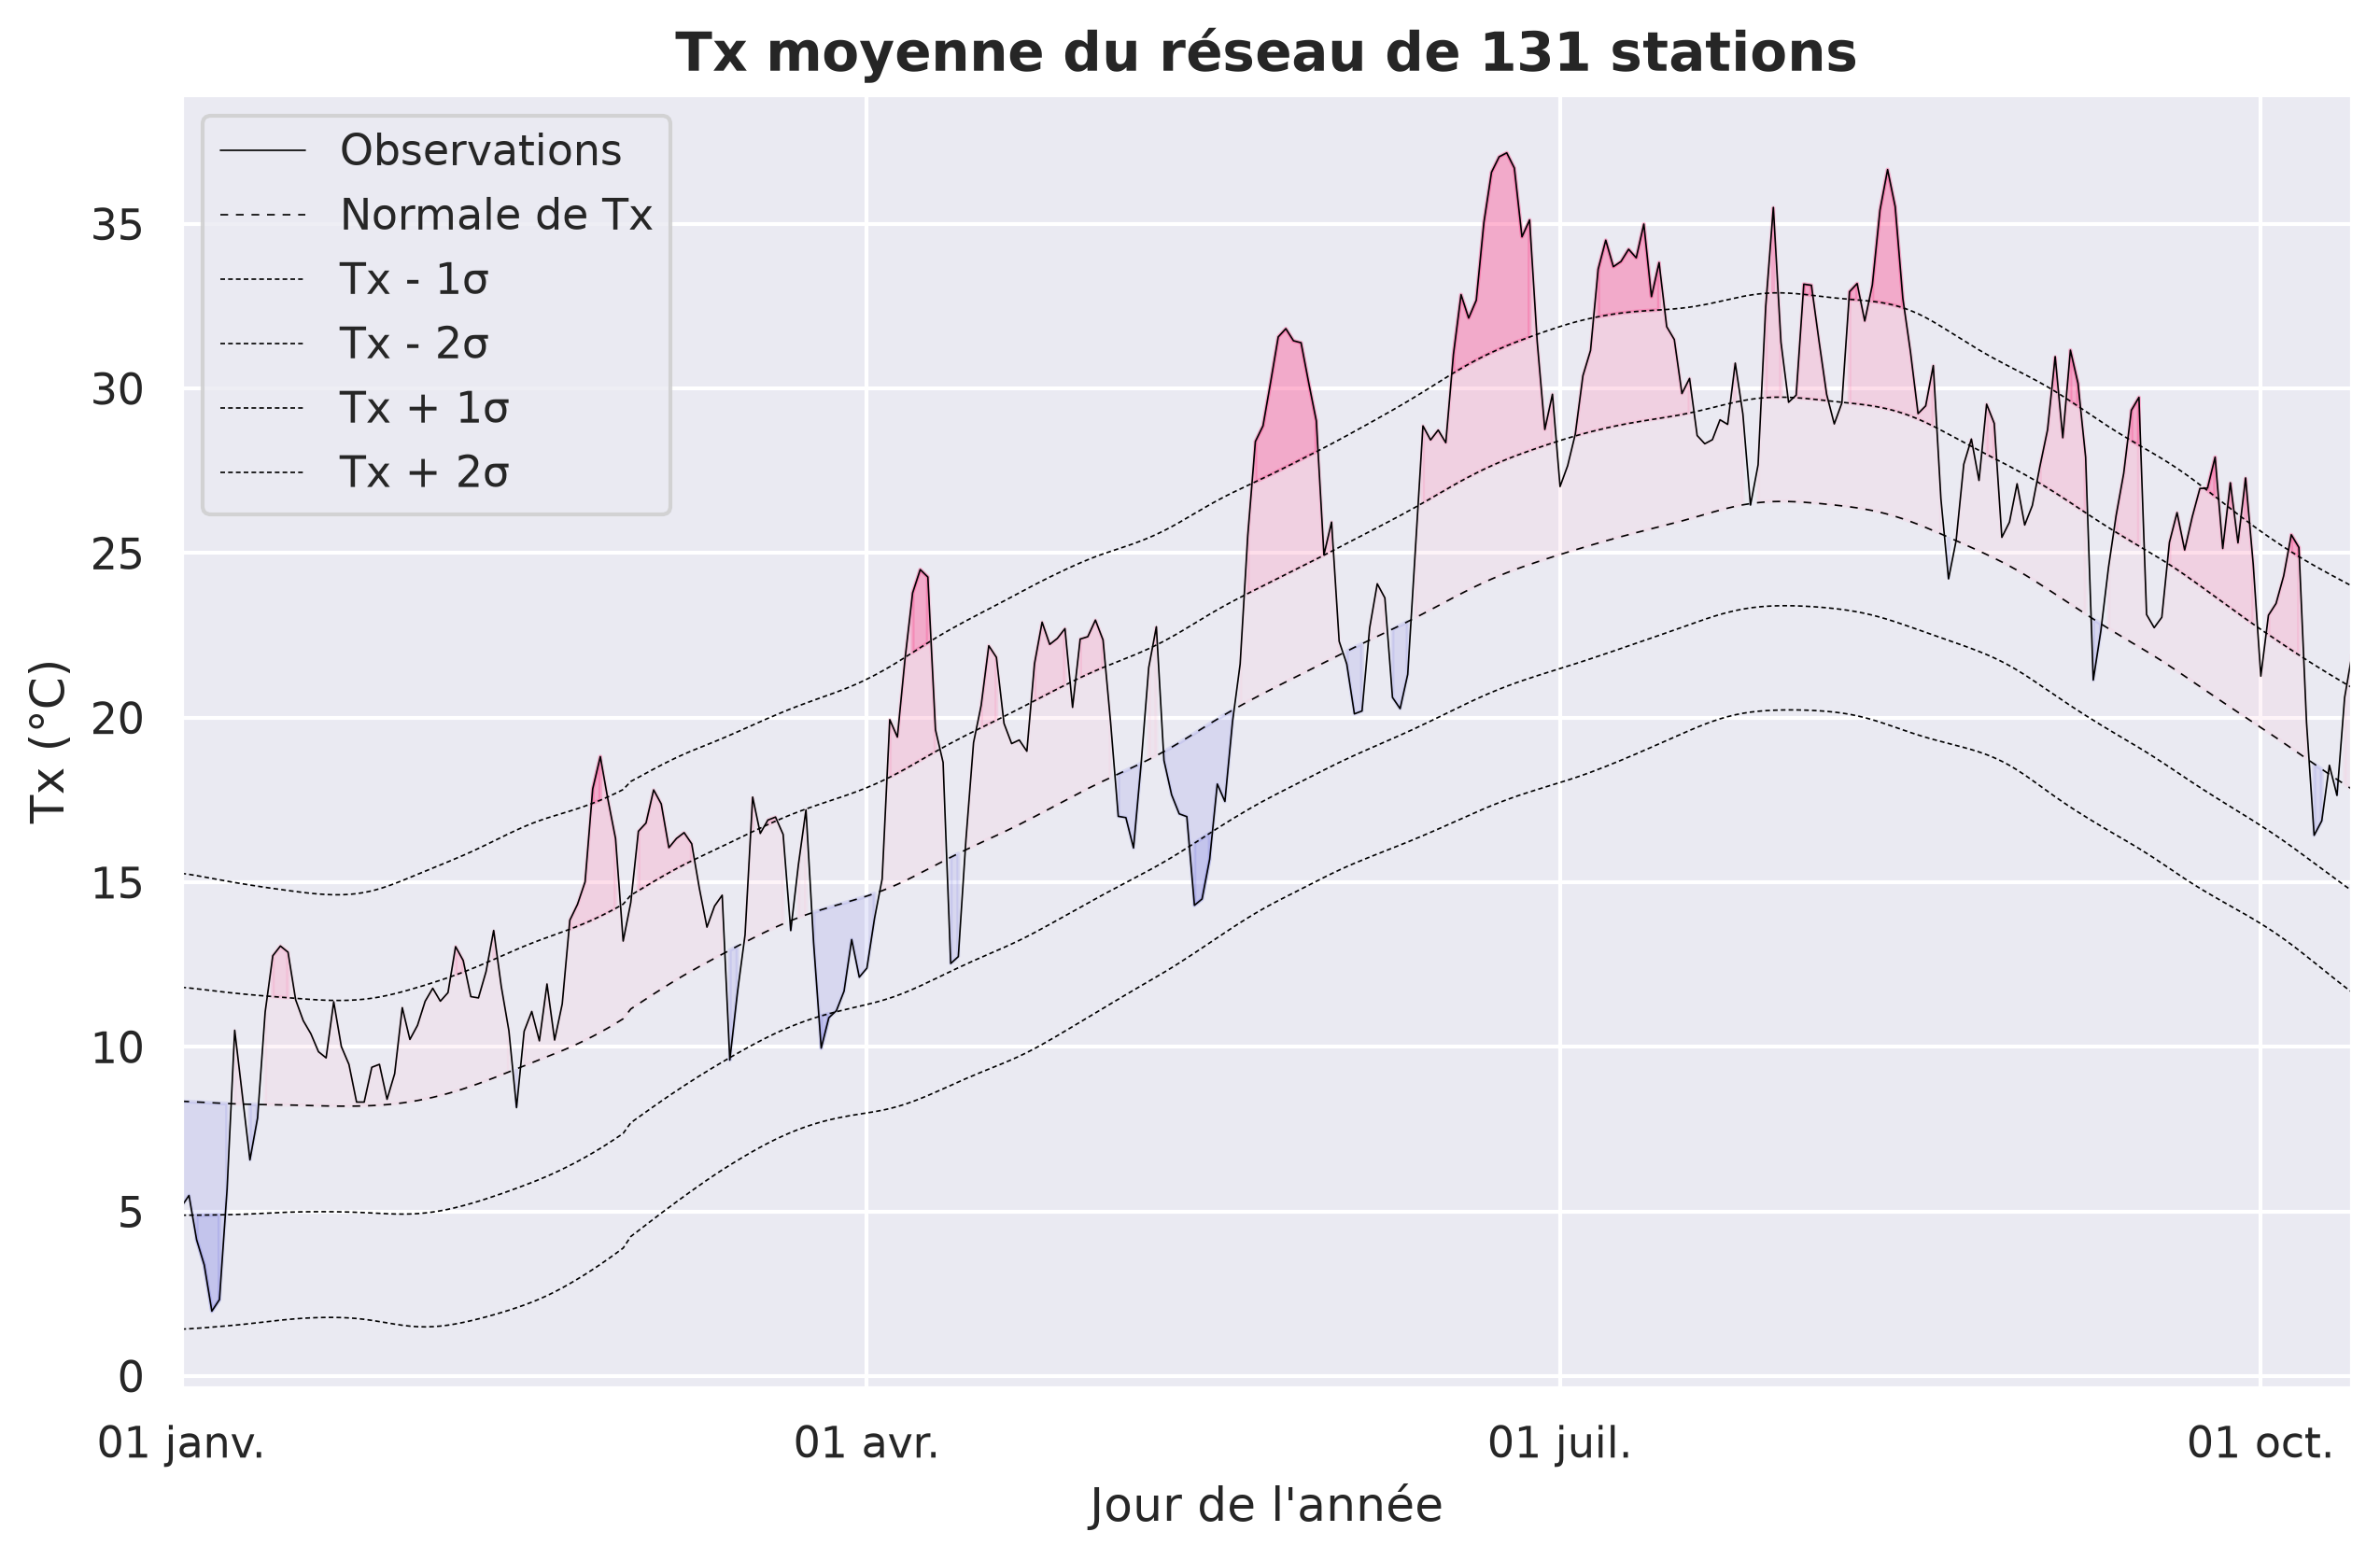

In [73]:
from matplotlib.ticker import FuncFormatter

# Set default style for all plots
sns.set_theme(style="darkgrid")

# Set dpi for better resolution
plt.rcParams['figure.dpi'] = 300

# Configure plot sizes
plt.rcParams['figure.figsize'] = (10, 6)

x = df_obs_2026_panel_plot["obs_date"].to_list()
y = df_obs_2026_panel_plot["tx"].to_numpy()
y_mean = df_obs_2026_panel_plot["tx_mean_smooth"].to_numpy()
y_std_m2 = df_obs_2026_panel_plot["tx_minus_2sigma"].to_numpy()
y_std_m1 = df_obs_2026_panel_plot["tx_minus_1sigma"].to_numpy()
y_std_p1 = df_obs_2026_panel_plot["tx_plus_1sigma"].to_numpy()
y_std_p2 = df_obs_2026_panel_plot["tx_plus_2sigma"].to_numpy()

fig, ax = plt.subplots()


ax.fill_between(x, y, y_mean, np.where(y < y_mean, y, 0), color="#8485E4", alpha=0.18)
ax.fill_between(x, y, y_std_m1, np.where(y < y_std_m1, y, 0), color="#6C6EE1", alpha=0.18)
ax.fill_between(x, y, y_std_m2, np.where(y < y_std_m2, y, 0), color="#4345E0", alpha=0.18)
ax.fill_between(x, y_mean, y, np.where(y > y_mean, y, 0), color="#FBC4D9", alpha=0.18)
ax.fill_between(x, y_std_p1, y, np.where(y > y_std_p1, y, 0), color="#FF7AAD", alpha=0.18)
ax.fill_between(x, y_std_p2, y, np.where(y > y_std_p2, y, 0), color="#FE0162", alpha=0.18)
ax.plot(x, y, color="#000000", linewidth=0.4, label="Observations")
ax.plot(x, y_mean, color="#000000", linewidth=0.4, linestyle=(0, (5, 5)), label="Normale de Tx")
ax.plot(x, y_std_m1, color="#000000", linewidth=0.4, linestyle=(0, (3, 2)), label="Tx - 1σ")
ax.plot(x, y_std_m2, color="#000000", linewidth=0.4, linestyle=(0, (3, 2)), label="Tx - 2σ")
ax.plot(x, y_std_p1, color="#000000", linewidth=0.4, linestyle=(0, (3, 2)), label="Tx + 1σ")
ax.plot(x, y_std_p2, color="#000000", linewidth=0.4, linestyle=(0, (3, 2)), label="Tx + 2σ")

ax.set_title("Tx moyenne du réseau de 131 stations", fontsize=14, fontweight="bold")
ax.set_xlabel("Jour de l'année", fontsize=12)
ax.set_ylabel("Tx (°C)", fontsize=12)

ax.set_xlim(date(2026, 1, 1), date(2026, 10, 13))

ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
ax.xaxis.set_major_formatter(FuncFormatter(format_day_month))

ax.legend()
# fig.autofmt_xdate()

plt.show()

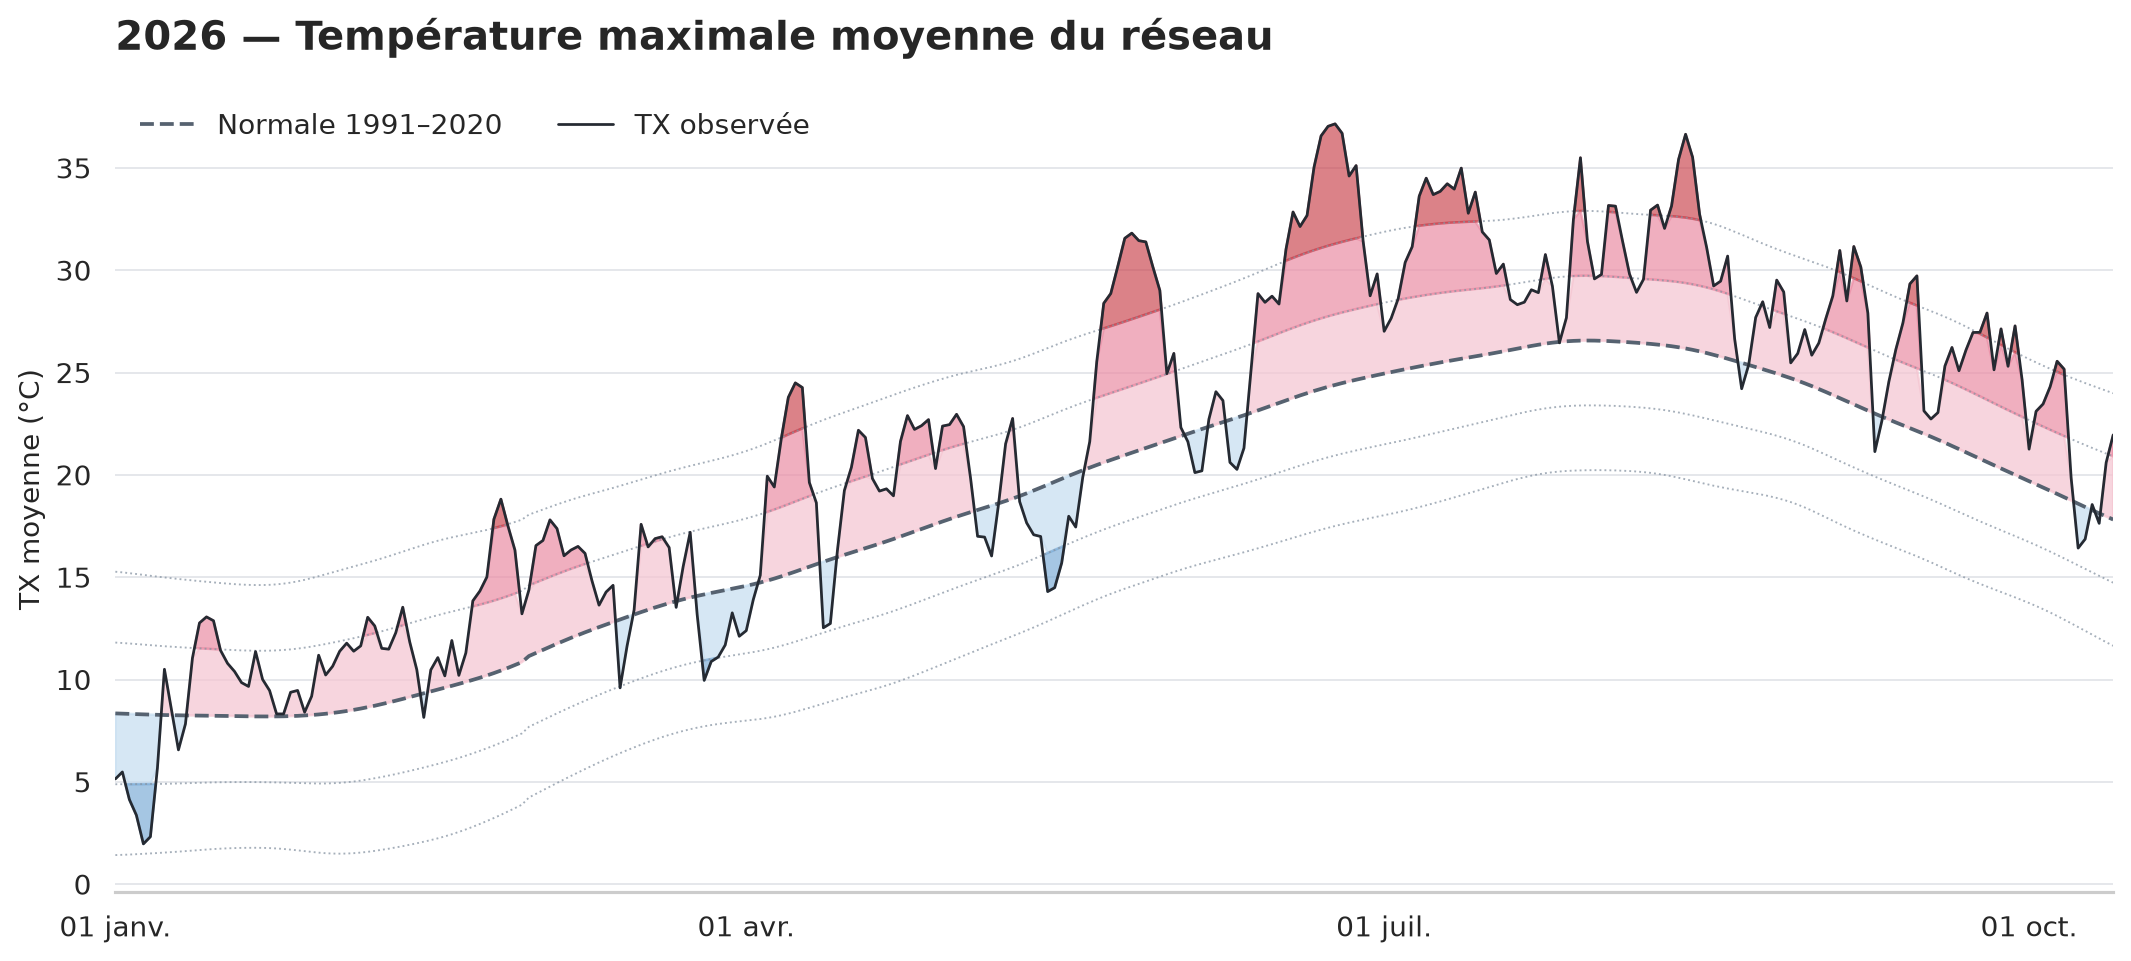

In [ ]:
sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(12, 5.5), dpi=180)

# Zones chaudes : couleurs plus soutenues à chaque seuil
ax.fill_between(
    x, y_mean, np.minimum(y, y_std_p1),
    where=y > y_mean,
    color="#F5C4D0", alpha=0.7, interpolate=True,
)
ax.fill_between(
    x, y_std_p1, np.minimum(y, y_std_p2),
    where=y > y_std_p1,
    color="#EB8DA5", alpha=0.7, interpolate=True,
)
ax.fill_between(
    x, y_std_p2, y,
    where=y > y_std_p2,
    color="#C83F49", alpha=0.65, interpolate=True,
)

# Zones froides
ax.fill_between(
    x, np.maximum(y, y_std_m1), y_mean,
    where=y < y_mean,
    color="#C5DDF0", alpha=0.7, interpolate=True,
)
ax.fill_between(
    x, np.maximum(y, y_std_m2), y_std_m1,
    where=y < y_std_m1,
    color="#7FAED8", alpha=0.7, interpolate=True,
)
ax.fill_between(
    x, y, y_std_m2,
    where=y < y_std_m2,
    color="#3266B0", alpha=0.65, interpolate=True,
)

# Limites climatologiques discrètes
for bound in [y_std_m2, y_std_m1, y_std_p1, y_std_p2]:
    ax.plot(
        x, bound,
        color="#8794A3", linewidth=0.75,
        linestyle=":", alpha=0.75,
    )

ax.plot(
    x, y_mean,
    color="#566270", linewidth=1.5,
    linestyle="--",
    label="Normale 1991–2020",
)

ax.plot(
    x, y,
    color="#252A32", linewidth=1.1,
    label="TX observée",
)

ax.set_title(
    "2026 - Température maximale moyenne du réseau",
    fontsize=16, fontweight="bold",
    loc="left", pad=15,
)
ax.set_ylabel("TX moyenne (°C)", fontsize=11)
ax.set_xlabel("")

ax.set_xlim(date(2026, 1, 1), date(2026, 10, 13))
ax.xaxis.set_major_locator(
    mdates.MonthLocator(bymonth=[1, 4, 7, 10])
)
ax.xaxis.set_major_formatter(FuncFormatter(format_day_month))

ax.grid(axis="x", visible=False)
ax.grid(axis="y", color="#E5E7EB", linewidth=0.8)

ax.spines[["top", "right", "left"]].set_visible(False)
ax.legend(loc="upper left", frameon=False, ncol=2)

fig.tight_layout()
plt.show()


### obs_w_normals

#### Add z-scores

In [ ]:
columns_select_normals_before = ["station_id", "clim_day"]
for param in params:
    columns_select_normals_before.extend([
        pl.col(f"{param}_mean_smooth"),
        pl.col(f"{param}_std_smooth"),
        # pl.col(f"{param}_lt_2sigma"),
        # pl.col(f"{param}_lt_1sigma"),
        # pl.col(f"{param}_gt_1sigma"),
        # pl.col(f"{param}_gt_2sigma"),
    ])

columns_select_obs_after = ["station_id", "station_name", "obs_date", "clim_day", "year", "month", "day"]
for param in params:
    columns_select_obs_after.extend([
        pl.col(param),
        pl.col(f"z_{param}"),
        pl.col(f"{param}_mean_smooth"),
        pl.col(f"{param}_std_smooth"),
        pl.col(f"ano_{param}"),
    ])

    if param != "tampli":
        columns_select_obs_after.append(
            pl.col(f"z_class_{param}"),
        )

expressions = []
z_class_expressions = []
for param in params:
    expressions.append((pl.col(param) - pl.col(f"{param}_mean_smooth")).alias(f"ano_{param}"))
    expressions.append(((pl.col(param) - pl.col(f"{param}_mean_smooth")) / pl.col(f"{param}_std_smooth")).alias(f"z_{param}"))

    if param != "tampli":
        col = f"z_{param}"
        z_class_expressions.append(
            pl.when(pl.col(col).is_null())
            .then(pl.lit(None, dtype=pl.String))
            .when(pl.col(col) < -2)
            .then(pl.lit("1 - Très froid"))
            .when(pl.col(col) < -1)
            .then(pl.lit("2 - Froid"))
            .when(pl.col(col) <= 1)
            .then(pl.lit("3 - Proche normale"))
            .when(pl.col(col) <= 2)
            .then(pl.lit("4 - Chaud"))
            .otherwise(pl.lit("5 - Très chaud"))
            .alias(f"z_class_{param}")
        )


df_obs_w_normals = (
    df_obs
    .join(
        df_daily_normals.select(columns_select_normals_before),
        how="inner",
        on=["station_id", "clim_day"],
    )
    .with_columns(expressions)
    .with_columns(z_class_expressions)
    .select(columns_select_obs_after)
    .sort("station_id", "obs_date")
)

: 

In [22]:
print(df_obs_w_normals.shape)
df_obs_parquet_2026 = (
    df_obs_w_normals
    .filter(pl.col("obs_date") >= date(2026, 1, 1))
    .join(
        df_station_coordinates.select("station_id", "altitude", "latitude", "longitude"),
        on="station_id",
        how="left",
    )
    .select(
        *columns_select_obs_after[:2],
        "altitude", "latitude", "longitude",
        *columns_select_obs_after[2:],
    )
)

print(df_obs_parquet_2026)

ts= utc_now_iso()

df_obs_parquet_2026.write_parquet(
    config.PROJECT_ROOT / "dump" / f"climato_obs_131_20260101_20261013_{ts}.parquet",
    compression="zstd",
)

(4436267, 30)
shape: (37_457, 33)
┌───────────┬───────────┬──────────┬───────────┬───┬───────────┬───────────┬───────────┬───────────┐
│ station_i ┆ station_n ┆ altitude ┆ latitude  ┆ … ┆ z_tampli  ┆ tampli_me ┆ tampli_st ┆ ano_tampl │
│ d         ┆ ame       ┆ ---      ┆ ---       ┆   ┆ ---       ┆ an_smooth ┆ d_smooth  ┆ i         │
│ ---       ┆ ---       ┆ i16      ┆ f64       ┆   ┆ f64       ┆ ---       ┆ ---       ┆ ---       │
│ str       ┆ str       ┆          ┆           ┆   ┆           ┆ f64       ┆ f64       ┆ f64       │
╞═══════════╪═══════════╪══════════╪═══════════╪═══╪═══════════╪═══════════╪═══════════╪═══════════╡
│ 01089001  ┆ AMBERIEU  ┆ 250      ┆ 45.9765   ┆ … ┆ 1.752516  ┆ 6.296177  ┆ 3.539952  ┆ 6.203823  │
│ 01089001  ┆ AMBERIEU  ┆ 250      ┆ 45.9765   ┆ … ┆ 1.744028  ┆ 6.318384  ┆ 3.544448  ┆ 6.181616  │
│ 01089001  ┆ AMBERIEU  ┆ 250      ┆ 45.9765   ┆ … ┆ 0.156794  ┆ 6.343483  ┆ 3.549363  ┆ 0.556517  │
│ 01089001  ┆ AMBERIEU  ┆ 250      ┆ 45.9765   ┆ … ┆ 0.45

#### Explore obs with normals / z-scores

In [ ]:
head_obs_z_tx = (
    df_obs_w_normals
    .lazy()
    .drop_nulls(["z_tn", "z_tx"])
    .filter(
        # pl.col("month") == 12,
        # pl.col("station_id") == "54526001",
        # pl.col("station_id").str.starts_with("13"),
    )
    # .with_columns((pl.col("z_tx") - pl.col("z_tn")).alias("z_tx_tn"))
    .sort(pl.col("z_tx"), descending=True)
    .head(100)
    .collect()
)

with pl.Config(tbl_rows=100, tbl_cols=50, tbl_width_chars=500):
    print(head_obs_z_tx)

shape: (100, 27)
┌────────────┬────────────────────┬────────────┬──────────┬──────┬───────┬─────┬──────┬───────────┬────────────────┬───────────────┬───────────┬──────┬──────────┬────────────────┬───────────────┬───────────┬───────┬──────────┬───────────────────┬──────────────────┬───────────┬────────┬──────────┬────────────────────┬───────────────────┬────────────┐
│ station_id ┆ station_name       ┆ obs_date   ┆ clim_day ┆ year ┆ month ┆ day ┆ tn   ┆ z_tn      ┆ tn_mean_smooth ┆ tn_std_smooth ┆ ano_tn    ┆ tx   ┆ z_tx     ┆ tx_mean_smooth ┆ tx_std_smooth ┆ ano_tx    ┆ tntxm ┆ z_tntxm  ┆ tntxm_mean_smooth ┆ tntxm_std_smooth ┆ ano_tntxm ┆ tampli ┆ z_tampli ┆ tampli_mean_smooth ┆ tampli_std_smooth ┆ ano_tampli │
│ ---        ┆ ---                ┆ ---        ┆ ---      ┆ ---  ┆ ---   ┆ --- ┆ ---  ┆ ---       ┆ ---            ┆ ---           ┆ ---       ┆ ---  ┆ ---      ┆ ---            ┆ ---           ┆ ---       ┆ ---   ┆ ---      ┆ ---               ┆ ---              ┆ ---       ┆ -

In [ ]:
head_obs = (
    df_obs_w_normals
    .lazy()
    .drop_nulls(["z_tn", "z_tx"])
    .filter(
        # pl.col("station_id") == "54526001",
        pl.col("station_id").str.starts_with("79"),
    )
    .sort(pl.col("z_tx"), descending=True)
    .head(100)
    .collect()
)

with pl.Config(tbl_rows=100, tbl_cols=50, tbl_width_chars=500):
    print(head_obs)

shape: (100, 27)
┌────────────┬────────────────┬────────────┬──────────┬──────┬───────┬─────┬──────┬───────────┬────────────────┬───────────────┬───────────┬──────┬──────────┬────────────────┬───────────────┬───────────┬───────┬──────────┬───────────────────┬──────────────────┬───────────┬────────┬──────────┬────────────────────┬───────────────────┬────────────┐
│ station_id ┆ station_name   ┆ obs_date   ┆ clim_day ┆ year ┆ month ┆ day ┆ tn   ┆ z_tn      ┆ tn_mean_smooth ┆ tn_std_smooth ┆ ano_tn    ┆ tx   ┆ z_tx     ┆ tx_mean_smooth ┆ tx_std_smooth ┆ ano_tx    ┆ tntxm ┆ z_tntxm  ┆ tntxm_mean_smooth ┆ tntxm_std_smooth ┆ ano_tntxm ┆ tampli ┆ z_tampli ┆ tampli_mean_smooth ┆ tampli_std_smooth ┆ ano_tampli │
│ ---        ┆ ---            ┆ ---        ┆ ---      ┆ ---  ┆ ---   ┆ --- ┆ ---  ┆ ---       ┆ ---            ┆ ---           ┆ ---       ┆ ---  ┆ ---      ┆ ---            ┆ ---           ┆ ---       ┆ ---   ┆ ---      ┆ ---               ┆ ---              ┆ ---       ┆ ---    ┆ --- 

In [ ]:
head_obs_tx = df_obs_w_normals.lazy().drop_nulls("tx").sort("tx", descending=True).head(100).collect()
with pl.Config(tbl_rows=100, tbl_cols=50, tbl_width_chars=500):
    print(head_obs_tx)

shape: (100, 27)
┌────────────┬─────────────────────────────┬────────────┬──────────┬──────┬───────┬─────┬──────┬───────────┬────────────────┬───────────────┬───────────┬──────┬──────────┬────────────────┬───────────────┬───────────┬───────┬──────────┬───────────────────┬──────────────────┬───────────┬────────┬──────────┬────────────────────┬───────────────────┬────────────┐
│ station_id ┆ station_name                ┆ obs_date   ┆ clim_day ┆ year ┆ month ┆ day ┆ tn   ┆ z_tn      ┆ tn_mean_smooth ┆ tn_std_smooth ┆ ano_tn    ┆ tx   ┆ z_tx     ┆ tx_mean_smooth ┆ tx_std_smooth ┆ ano_tx    ┆ tntxm ┆ z_tntxm  ┆ tntxm_mean_smooth ┆ tntxm_std_smooth ┆ ano_tntxm ┆ tampli ┆ z_tampli ┆ tampli_mean_smooth ┆ tampli_std_smooth ┆ ano_tampli │
│ ---        ┆ ---                         ┆ ---        ┆ ---      ┆ ---  ┆ ---   ┆ --- ┆ ---  ┆ ---       ┆ ---            ┆ ---           ┆ ---       ┆ ---  ┆ ---      ┆ ---            ┆ ---           ┆ ---       ┆ ---   ┆ ---      ┆ ---               ┆ ---  

In [ ]:
head_obs_z_tx = (
    df_obs_w_normals
    .lazy()
    .drop_nulls(["z_tn", "z_tx"])
    .filter(
        pl.col("obs_date") >= date(2026, 10, 1),
    )
    # .with_columns((pl.col("z_tx") - pl.col("z_tn")).alias("z_tx_tn"))
    .sort(pl.col("z_tx"), descending=True)
    .head(100)
    .collect()
)

with pl.Config(tbl_rows=100, tbl_cols=50, tbl_width_chars=500):
    print(head_obs_z_tx)

shape: (100, 27)
┌────────────┬─────────────────────────────┬────────────┬──────────┬──────┬───────┬─────┬──────┬───────────┬────────────────┬───────────────┬───────────┬──────┬──────────┬────────────────┬───────────────┬───────────┬───────┬──────────┬───────────────────┬──────────────────┬───────────┬────────┬──────────┬────────────────────┬───────────────────┬────────────┐
│ station_id ┆ station_name                ┆ obs_date   ┆ clim_day ┆ year ┆ month ┆ day ┆ tn   ┆ z_tn      ┆ tn_mean_smooth ┆ tn_std_smooth ┆ ano_tn    ┆ tx   ┆ z_tx     ┆ tx_mean_smooth ┆ tx_std_smooth ┆ ano_tx    ┆ tntxm ┆ z_tntxm  ┆ tntxm_mean_smooth ┆ tntxm_std_smooth ┆ ano_tntxm ┆ tampli ┆ z_tampli ┆ tampli_mean_smooth ┆ tampli_std_smooth ┆ ano_tampli │
│ ---        ┆ ---                         ┆ ---        ┆ ---      ┆ ---  ┆ ---   ┆ --- ┆ ---  ┆ ---       ┆ ---            ┆ ---           ┆ ---       ┆ ---  ┆ ---      ┆ ---            ┆ ---           ┆ ---       ┆ ---   ┆ ---      ┆ ---               ┆ ---  

In [ ]:
head_obs_z_tx = (
    df_obs_w_normals
    .lazy()
    .drop_nulls(["z_tn", "z_tx"])
    .filter(
        pl.col("obs_date") == date(2026, 10, 13),
    )
    # .with_columns((pl.col("z_tx") - pl.col("z_tn")).alias("z_tx_tn"))
    .sort(pl.col("z_tx"), descending=True)
    .head(500)
    .collect()
)

with pl.Config(tbl_rows=400, tbl_cols=50, tbl_width_chars=500):
    print(head_obs_z_tx)

shape: (333, 27)
┌────────────┬────────────────────────────────┬────────────┬──────────┬──────┬───────┬─────┬──────┬───────────┬────────────────┬───────────────┬───────────┬──────┬───────────┬────────────────┬───────────────┬───────────┬───────┬───────────┬───────────────────┬──────────────────┬───────────┬────────┬───────────┬────────────────────┬───────────────────┬────────────┐
│ station_id ┆ station_name                   ┆ obs_date   ┆ clim_day ┆ year ┆ month ┆ day ┆ tn   ┆ z_tn      ┆ tn_mean_smooth ┆ tn_std_smooth ┆ ano_tn    ┆ tx   ┆ z_tx      ┆ tx_mean_smooth ┆ tx_std_smooth ┆ ano_tx    ┆ tntxm ┆ z_tntxm   ┆ tntxm_mean_smooth ┆ tntxm_std_smooth ┆ ano_tntxm ┆ tampli ┆ z_tampli  ┆ tampli_mean_smooth ┆ tampli_std_smooth ┆ ano_tampli │
│ ---        ┆ ---                            ┆ ---        ┆ ---      ┆ ---  ┆ ---   ┆ --- ┆ ---  ┆ ---       ┆ ---            ┆ ---           ┆ ---       ┆ ---  ┆ ---       ┆ ---            ┆ ---           ┆ ---       ┆ ---   ┆ ---       ┆ ---     

In [ ]:
head_obs_z_tx = (
    df_obs_w_normals
    .lazy()
    .drop_nulls(["z_tn", "z_tx"])
    .filter(
        pl.col("obs_date") == date(2026, 10, 13),
    )
    # .with_columns((pl.col("z_tx") - pl.col("z_tn")).alias("z_tx_tn"))
    .sort(pl.col("z_tn"), descending=True)
    .head(500)
    .collect()
)

with pl.Config(tbl_rows=400, tbl_cols=50, tbl_width_chars=500):
    print(head_obs_z_tx)

shape: (333, 27)
┌────────────┬────────────────────────────────┬────────────┬──────────┬──────┬───────┬─────┬──────┬───────────┬────────────────┬───────────────┬───────────┬──────┬───────────┬────────────────┬───────────────┬───────────┬───────┬───────────┬───────────────────┬──────────────────┬───────────┬────────┬───────────┬────────────────────┬───────────────────┬────────────┐
│ station_id ┆ station_name                   ┆ obs_date   ┆ clim_day ┆ year ┆ month ┆ day ┆ tn   ┆ z_tn      ┆ tn_mean_smooth ┆ tn_std_smooth ┆ ano_tn    ┆ tx   ┆ z_tx      ┆ tx_mean_smooth ┆ tx_std_smooth ┆ ano_tx    ┆ tntxm ┆ z_tntxm   ┆ tntxm_mean_smooth ┆ tntxm_std_smooth ┆ ano_tntxm ┆ tampli ┆ z_tampli  ┆ tampli_mean_smooth ┆ tampli_std_smooth ┆ ano_tampli │
│ ---        ┆ ---                            ┆ ---        ┆ ---      ┆ ---  ┆ ---   ┆ --- ┆ ---  ┆ ---       ┆ ---            ┆ ---           ┆ ---       ┆ ---  ┆ ---       ┆ ---            ┆ ---           ┆ ---       ┆ ---   ┆ ---       ┆ ---     

In [ ]:
head_obs_z_tx_85 = (
    df_obs_w_normals
    .lazy()
    .drop_nulls(["z_tn", "z_tx"])
    .filter(
        pl.col("obs_date") == date(2026, 6, 24),
        # pl.col("month") == 12,
        # pl.col("station_id") == "54526001",
        pl.col("station_id").str.starts_with("85"),
    )
    # .with_columns((pl.col("z_tx") - pl.col("z_tn")).alias("z_tx_tn"))
    .sort(pl.col("z_tx"), descending=True)
    .head(100)
    .collect()
)

with pl.Config(tbl_rows=100, tbl_cols=50, tbl_width_chars=500):
    print(head_obs_z_tx_85)

shape: (5, 27)
┌────────────┬─────────────────────────────┬────────────┬──────────┬──────┬───────┬─────┬──────┬──────────┬────────────────┬───────────────┬───────────┬──────┬──────────┬────────────────┬───────────────┬───────────┬───────┬──────────┬───────────────────┬──────────────────┬───────────┬────────┬──────────┬────────────────────┬───────────────────┬────────────┐
│ station_id ┆ station_name                ┆ obs_date   ┆ clim_day ┆ year ┆ month ┆ day ┆ tn   ┆ z_tn     ┆ tn_mean_smooth ┆ tn_std_smooth ┆ ano_tn    ┆ tx   ┆ z_tx     ┆ tx_mean_smooth ┆ tx_std_smooth ┆ ano_tx    ┆ tntxm ┆ z_tntxm  ┆ tntxm_mean_smooth ┆ tntxm_std_smooth ┆ ano_tntxm ┆ tampli ┆ z_tampli ┆ tampli_mean_smooth ┆ tampli_std_smooth ┆ ano_tampli │
│ ---        ┆ ---                         ┆ ---        ┆ ---      ┆ ---  ┆ ---   ┆ --- ┆ ---  ┆ ---      ┆ ---            ┆ ---           ┆ ---       ┆ ---  ┆ ---      ┆ ---            ┆ ---           ┆ ---       ┆ ---   ┆ ---      ┆ ---               ┆ ---       

In [ ]:
head_obs_z_tx_83 = (
    df_obs_w_normals
    .lazy()
    .drop_nulls(["z_tn", "z_tx"])
    .filter(
        pl.col("obs_date") == date(2026, 9, 5),
        # pl.col("month") == 12,
        # pl.col("station_id") == "54526001",
        pl.col("station_id").str.starts_with("83"),
    )
    # .with_columns((pl.col("z_tx") - pl.col("z_tn")).alias("z_tx_tn"))
    .sort(pl.col("z_tx"), descending=True)
    .head(100)
    .collect()
)

with pl.Config(tbl_rows=100, tbl_cols=50, tbl_width_chars=500):
    print(head_obs_z_tx_83)

shape: (6, 27)
┌────────────┬────────────────────┬────────────┬──────────┬──────┬───────┬─────┬──────┬──────────┬────────────────┬───────────────┬──────────┬──────┬──────────┬────────────────┬───────────────┬───────────┬───────┬──────────┬───────────────────┬──────────────────┬───────────┬────────┬──────────┬────────────────────┬───────────────────┬────────────┐
│ station_id ┆ station_name       ┆ obs_date   ┆ clim_day ┆ year ┆ month ┆ day ┆ tn   ┆ z_tn     ┆ tn_mean_smooth ┆ tn_std_smooth ┆ ano_tn   ┆ tx   ┆ z_tx     ┆ tx_mean_smooth ┆ tx_std_smooth ┆ ano_tx    ┆ tntxm ┆ z_tntxm  ┆ tntxm_mean_smooth ┆ tntxm_std_smooth ┆ ano_tntxm ┆ tampli ┆ z_tampli ┆ tampli_mean_smooth ┆ tampli_std_smooth ┆ ano_tampli │
│ ---        ┆ ---                ┆ ---        ┆ ---      ┆ ---  ┆ ---   ┆ --- ┆ ---  ┆ ---      ┆ ---            ┆ ---           ┆ ---      ┆ ---  ┆ ---      ┆ ---            ┆ ---           ┆ ---       ┆ ---   ┆ ---      ┆ ---               ┆ ---              ┆ ---       ┆ ---    ┆ 

In [ ]:
lf_winter_niort = (
    df_obs_w_normals
    .lazy()
    .drop_nulls(["z_tn", "z_tx"])
    .filter(
        pl.col("obs_date").dt.month().is_in([12, 1, 2]),
        # pl.col("month") == 12,
        pl.col("station_id") == "79191005",
        # pl.col("station_id").str.starts_with("85"),
    )
    # .with_columns((pl.col("z_tx") - pl.col("z_tn")).alias("z_tx_tn"))
)

df_winter_z_tx_desc_niort = (
    lf_winter_niort
    .sort(pl.col("z_tx"), descending=True)
    .head(100)
    .collect()
)

df_winter_z_tx_asc_niort = (
    lf_winter_niort
    .sort(pl.col("z_tx"), descending=False)
    .head(100)
    .collect()
)

with pl.Config(tbl_rows=100, tbl_cols=50, tbl_width_chars=500):
    print(df_winter_z_tx_desc_niort)

with pl.Config(tbl_rows=100, tbl_cols=50, tbl_width_chars=500):
    print(df_winter_z_tx_asc_niort)

shape: (100, 27)
┌────────────┬──────────────┬────────────┬──────────┬──────┬───────┬─────┬──────┬───────────┬────────────────┬───────────────┬───────────┬──────┬──────────┬────────────────┬───────────────┬───────────┬───────┬──────────┬───────────────────┬──────────────────┬───────────┬────────┬───────────┬────────────────────┬───────────────────┬────────────┐
│ station_id ┆ station_name ┆ obs_date   ┆ clim_day ┆ year ┆ month ┆ day ┆ tn   ┆ z_tn      ┆ tn_mean_smooth ┆ tn_std_smooth ┆ ano_tn    ┆ tx   ┆ z_tx     ┆ tx_mean_smooth ┆ tx_std_smooth ┆ ano_tx    ┆ tntxm ┆ z_tntxm  ┆ tntxm_mean_smooth ┆ tntxm_std_smooth ┆ ano_tntxm ┆ tampli ┆ z_tampli  ┆ tampli_mean_smooth ┆ tampli_std_smooth ┆ ano_tampli │
│ ---        ┆ ---          ┆ ---        ┆ ---      ┆ ---  ┆ ---   ┆ --- ┆ ---  ┆ ---       ┆ ---            ┆ ---           ┆ ---       ┆ ---  ┆ ---      ┆ ---            ┆ ---           ┆ ---       ┆ ---   ┆ ---      ┆ ---               ┆ ---              ┆ ---       ┆ ---    ┆ ---     

In [ ]:
lf_summer_niort = (
    df_obs_w_normals
    .lazy()
    .drop_nulls(["z_tn", "z_tx"])
    .filter(
        pl.col("obs_date").dt.month().is_in([6, 7, 8]),
        # pl.col("month") == 12,
        pl.col("station_id") == "79191005",
        # pl.col("station_id").str.starts_with("85"),
    )
    # .with_columns((pl.col("z_tx") - pl.col("z_tn")).alias("z_tx_tn"))
)

df_summer_z_tx_desc_niort = (
    lf_summer_niort
    .sort(pl.col("z_tx"), descending=True)
    .head(100)
    .collect()
)

df_summer_z_tx_asc_niort = (
    lf_summer_niort
    .sort(pl.col("z_tx"), descending=False)
    .head(100)
    .collect()
)

with pl.Config(tbl_rows=100, tbl_cols=50, tbl_width_chars=500):
    print(df_summer_z_tx_desc_niort)

with pl.Config(tbl_rows=100, tbl_cols=50, tbl_width_chars=500):
    print(df_summer_z_tx_asc_niort)

shape: (100, 27)
┌────────────┬──────────────┬────────────┬──────────┬──────┬───────┬─────┬──────┬───────────┬────────────────┬───────────────┬───────────┬──────┬──────────┬────────────────┬───────────────┬───────────┬───────┬──────────┬───────────────────┬──────────────────┬───────────┬────────┬──────────┬────────────────────┬───────────────────┬────────────┐
│ station_id ┆ station_name ┆ obs_date   ┆ clim_day ┆ year ┆ month ┆ day ┆ tn   ┆ z_tn      ┆ tn_mean_smooth ┆ tn_std_smooth ┆ ano_tn    ┆ tx   ┆ z_tx     ┆ tx_mean_smooth ┆ tx_std_smooth ┆ ano_tx    ┆ tntxm ┆ z_tntxm  ┆ tntxm_mean_smooth ┆ tntxm_std_smooth ┆ ano_tntxm ┆ tampli ┆ z_tampli ┆ tampli_mean_smooth ┆ tampli_std_smooth ┆ ano_tampli │
│ ---        ┆ ---          ┆ ---        ┆ ---      ┆ ---  ┆ ---   ┆ --- ┆ ---  ┆ ---       ┆ ---            ┆ ---           ┆ ---       ┆ ---  ┆ ---      ┆ ---            ┆ ---           ┆ ---       ┆ ---   ┆ ---      ┆ ---               ┆ ---              ┆ ---       ┆ ---    ┆ ---      ┆